## 1. Environment Setup & Database Connection

### 1.1 Importing important libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
import psycopg2

### 1.2 PostgreSQL Database Connection

In [2]:
from sqlalchemy import create_engine, text
from getpass import getpass
from sqlalchemy.engine import URL

password = getpass("Enter PostgreSQL password: ")

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="DataProject"
)

engine = create_engine(connection_url)

try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT version();"))
        print("Database connection successful!")
        print(result.fetchone()[0])
except Exception as e:
    print("Database connection failed:")
    print(e)

Database connection successful!
PostgreSQL 17.5 on x86_64-windows, compiled by msvc-19.43.34808, 64-bit


## 2. Inspect Analytics Schema

In [3]:
# List all tables in the analytics schema

query = """
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'analytics'
ORDER BY table_name;
"""

tables = pd.read_sql(query, engine)

tables

,table_name
0,campaign_features
1,customer_features
2,product_features


### 2.1 Inspect Analytics Table Structures

In [4]:
# Inspect columns and data types of all analytics tables

for table_name in tables["table_name"]:
    # print(f"\n{'=' * 60}")
    print(f"TABLE: analytics.{table_name}")
    # print(f"{'=' * 60}")

    query = f"""
    SELECT
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_schema = 'analytics'
      AND table_name = '{table_name}'
    ORDER BY ordinal_position;
    """

    structure = pd.read_sql(query, engine)
    display(structure)

TABLE: analytics.campaign_features


,column_name,data_type
0,household_key,bigint
1,campaigns_assigned,bigint
2,campaigns_redeemed,bigint
3,coupons_redeemed,bigint
4,campaign_redemption_rate,numeric


TABLE: analytics.customer_features


,column_name,data_type
0,household_key,bigint
1,total_baskets,bigint
2,active_days,bigint
3,unique_products,bigint
4,total_units_purchased,bigint
5,total_spend,numeric
6,avg_basket_value,numeric
7,avg_retail_discount,numeric
8,coupon_usage_rate,numeric
9,recency_days,bigint


TABLE: analytics.product_features


,column_name,data_type
0,product_id,bigint
1,department,character varying
2,brand,character varying
3,commodity_desc,character varying
4,sub_commodity_desc,character varying
5,manufacturer,integer
6,curr_size_of_product,character varying
7,total_units_sold,bigint
8,total_sales,numeric
9,unique_households,bigint


### 2.2 Analytics Table Size and Sample

In [5]:
# Check row counts and sample records for each analytics table

for table_name in tables["table_name"]:
    print(f"\n{'=' * 70}")
    print(f"TABLE: analytics.{table_name}")
    print(f"{'=' * 70}")

    # Row count
    count_query = f"""
    SELECT COUNT(*) AS row_count
    FROM analytics.{table_name};
    """

    row_count = pd.read_sql(count_query, engine).iloc[0, 0]
    print(f"Rows: {row_count:,}")

    # Sample records
    sample_query = f"""
    SELECT *
    FROM analytics.{table_name}
    LIMIT 5;
    """

    sample = pd.read_sql(sample_query, engine)
    display(sample)


TABLE: analytics.campaign_features
Rows: 1,584


,household_key,campaigns_assigned,campaigns_redeemed,coupons_redeemed,campaign_redemption_rate
0,1,8,2,5,0.25
1,2,1,0,0,0.00
2,3,3,0,0,0.00
3,4,1,0,0,0.00
4,6,4,0,0,0.00



TABLE: analytics.customer_features
Rows: 2,500


,household_key,total_baskets,active_days,unique_products,total_units_purchased,total_spend,avg_basket_value,avg_retail_discount,coupon_usage_rate,recency_days,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc
0,1,86,79,677,1997,4330.16,50.35,-0.4036,0.0614,5,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown
1,2,45,45,546,834,1954.34,43.43,-0.4692,0.0084,43,None,None,None,None,None,None,None
2,3,47,46,516,8540,2653.21,56.45,-0.7323,0.0575,8,None,None,None,None,None,None,None
3,4,30,30,164,382,1200.11,40.00,-0.3842,0.0033,84,None,None,None,None,None,None,None
4,5,40,33,199,245,779.06,19.48,-0.5330,0.0000,8,None,None,None,None,None,None,None



TABLE: analytics.product_features
Rows: 92,339


,product_id,department,brand,commodity_desc,sub_commodity_desc,manufacturer,curr_size_of_product,total_units_sold,total_sales,unique_households,unique_baskets,avg_unit_sales_value,avg_retail_discount,coupon_usage_rate
0,25671,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,2,22 LB,6,20.94,3,3,3.49,0.00,0.0
1,26081,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,2,,1,0.99,1,1,0.99,0.00,0.0
2,26093,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,69,,1,1.59,1,1,1.59,0.00,0.0
3,26190,GROCERY,Private,FRUIT - SHELF STABLE,APPLE SAUCE,69,50 OZ,1,1.54,1,1,1.54,0.00,0.0
4,26355,GROCERY,Private,COOKIES/CONES,SPECIALTY COOKIES,69,14 OZ,2,1.98,1,1,0.99,-0.52,0.0


## 3. Load Analytics Tables

In [6]:
# Load analytics tables into pandas DataFrames

customer_df = pd.read_sql("SELECT * FROM analytics.customer_features;", engine)

campaign_df = pd.read_sql("SELECT * FROM analytics.campaign_features;", engine)

product_df = pd.read_sql("SELECT * FROM analytics.product_features;", engine)

print("Customer data shape:", customer_df.shape)
print("Campaign data shape:", campaign_df.shape)
print("Product data shape:", product_df.shape)

Customer data shape: (2500, 17)
Campaign data shape: (1584, 5)
Product data shape: (92339, 14)


In [7]:
customer_df.head()

,household_key,total_baskets,active_days,unique_products,total_units_purchased,total_spend,avg_basket_value,avg_retail_discount,coupon_usage_rate,recency_days,age_desc,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc
0,1,86,79,677,1997,4330.16,50.35,-0.4036,0.0614,5,65+,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown
1,2,45,45,546,834,1954.34,43.43,-0.4692,0.0084,43,None,None,None,None,None,None,None
2,3,47,46,516,8540,2653.21,56.45,-0.7323,0.0575,8,None,None,None,None,None,None,None
3,4,30,30,164,382,1200.11,40.00,-0.3842,0.0033,84,None,None,None,None,None,None,None
4,5,40,33,199,245,779.06,19.48,-0.5330,0.0000,8,None,None,None,None,None,None,None


### 3.1 Combine Customer & Campaign Features

In [8]:
household_eda = customer_df.merge(
    campaign_df,
    on="household_key",
    how="left"
)

print("Household EDA shape:", household_eda.shape)

Household EDA shape: (2500, 21)


In [9]:
household_eda.head()

,household_key,total_baskets,active_days,unique_products,total_units_purchased,total_spend,avg_basket_value,avg_retail_discount,coupon_usage_rate,recency_days,...,marital_status_code,income_desc,homeowner_desc,hh_comp_desc,household_size_desc,kid_category_desc,campaigns_assigned,campaigns_redeemed,coupons_redeemed,campaign_redemption_rate
0,1,86,79,677,1997,4330.16,50.35,-0.4036,0.0614,5,...,A,35-49K,Homeowner,2 Adults No Kids,2,None/Unknown,8.0,2.0,5.0,0.25
1,2,45,45,546,834,1954.34,43.43,-0.4692,0.0084,43,...,None,None,None,None,None,None,1.0,0.0,0.0,0.00
2,3,47,46,516,8540,2653.21,56.45,-0.7323,0.0575,8,...,None,None,None,None,None,None,3.0,0.0,0.0,0.00
3,4,30,30,164,382,1200.11,40.00,-0.3842,0.0033,84,...,None,None,None,None,None,None,1.0,0.0,0.0,0.00
4,5,40,33,199,245,779.06,19.48,-0.5330,0.0000,8,...,None,None,None,None,None,None,NaN,NaN,NaN,NaN


In [10]:
household_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   household_key             2500 non-null   int64  
 1   total_baskets             2500 non-null   int64  
 2   active_days               2500 non-null   int64  
 3   unique_products           2500 non-null   int64  
 4   total_units_purchased     2500 non-null   int64  
 5   total_spend               2500 non-null   float64
 6   avg_basket_value          2500 non-null   float64
 7   avg_retail_discount       2500 non-null   float64
 8   coupon_usage_rate         2500 non-null   float64
 9   recency_days              2500 non-null   int64  
 10  age_desc                  801 non-null    object 
 11  marital_status_code       801 non-null    object 
 12  income_desc               801 non-null    object 
 13  homeowner_desc            801 non-null    object 
 14  hh_comp_

### 3.2 Validate Household-Level Merge

In [11]:
print("Customer households:", customer_df["household_key"].nunique())
print("Campaign households:", campaign_df["household_key"].nunique())
print("Merged households:", household_eda["household_key"].nunique())

print("\nCampaign-missing households:",
      household_eda["campaigns_assigned"].isna().sum())

Customer households: 2500
Campaign households: 1584
Merged households: 2500

Campaign-missing households: 916


In [12]:
# Check for duplicate household keys after merging
household_eda["household_key"].duplicated().sum()

0

# 4. Exploratory Data Analysis

## 4.1. Household-Level Descriptive Statistics

### 4.1.1. Numerical feautre analysis

In [13]:
behavior_cols = [
    "total_baskets",
    "active_days",
    "unique_products",
    "total_units_purchased",
    "total_spend",
    "avg_basket_value",
    "avg_retail_discount",
    "coupon_usage_rate",
    "recency_days"
]

household_eda[behavior_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
total_baskets,2500.0,110.593600,115.669368,1.0000,39.0000,79.0000,142.250000,1.300000e+03
active_days,2500.0,90.213200,76.317337,1.0000,34.0000,70.0000,124.000000,5.210000e+02
unique_products,2500.0,560.587600,435.957889,4.0000,230.7500,455.0000,788.000000,3.159000e+03
total_units_purchased,2500.0,104274.248800,244456.075850,5.0000,770.0000,11084.5000,87640.000000,4.479917e+06
total_spend,2500.0,3222.985232,3349.026076,8.1700,970.7400,2157.7500,4413.320000,3.831979e+04
avg_basket_value,2500.0,31.620732,19.054951,2.3900,18.3275,27.4200,40.547500,1.658300e+02
avg_retail_discount,2500.0,-0.559793,0.277976,-4.7522,-0.6374,-0.5044,-0.412675,-3.630000e-02
coupon_usage_rate,2500.0,0.011275,0.022314,0.0000,0.0000,0.0039,0.011725,2.588000e-01
recency_days,2500.0,25.574000,62.790655,0.0000,1.0000,6.0000,20.000000,6.570000e+02


### 4.1.2. Distribution of Household Behavior Variables

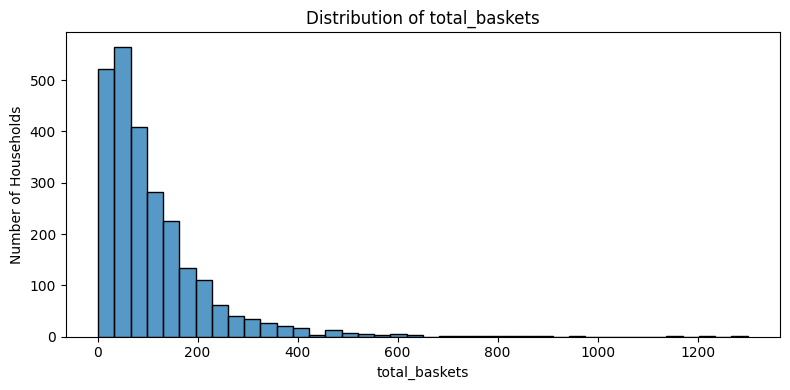

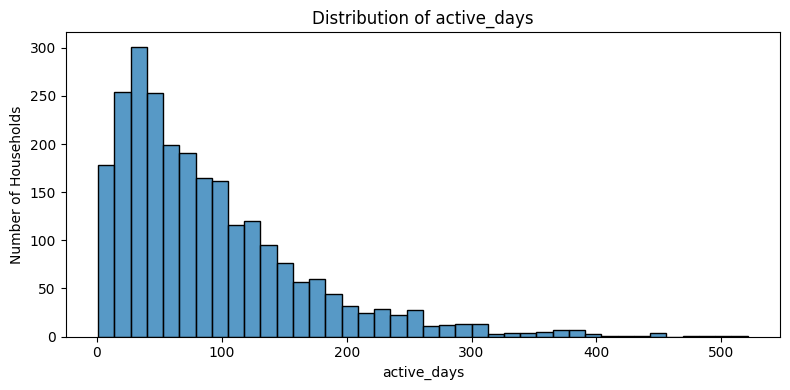

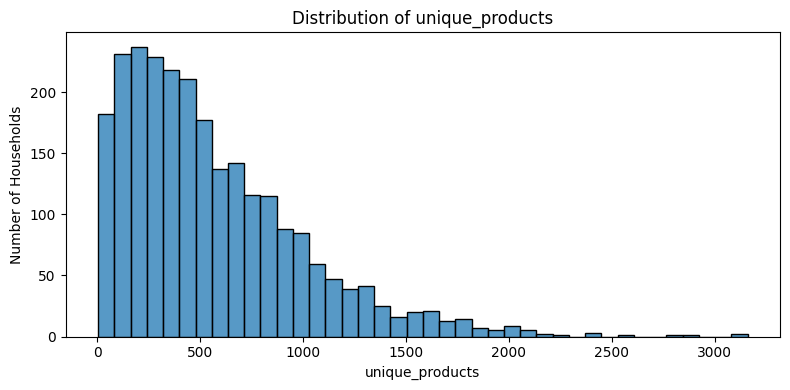

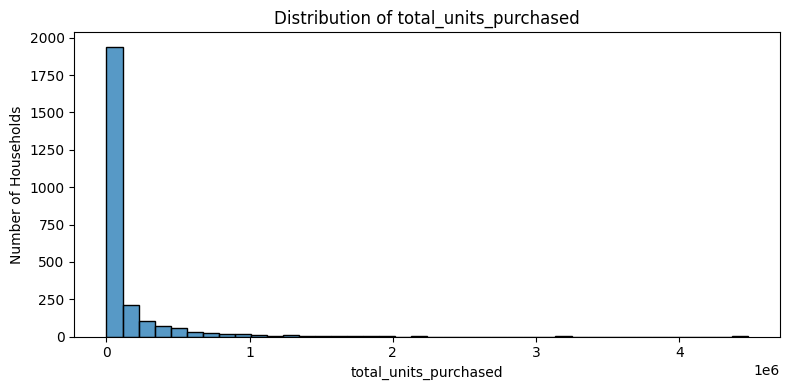

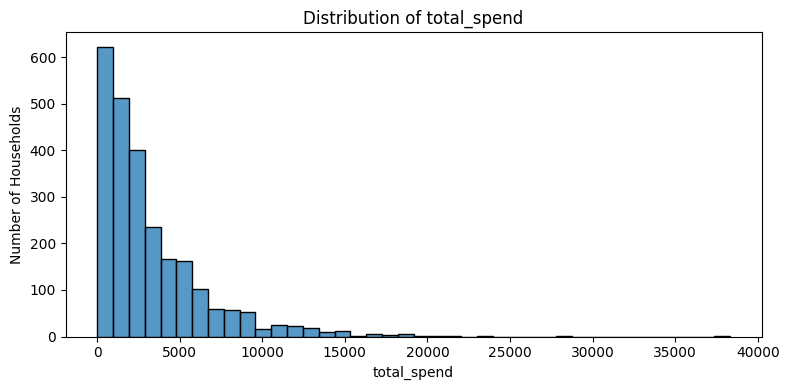

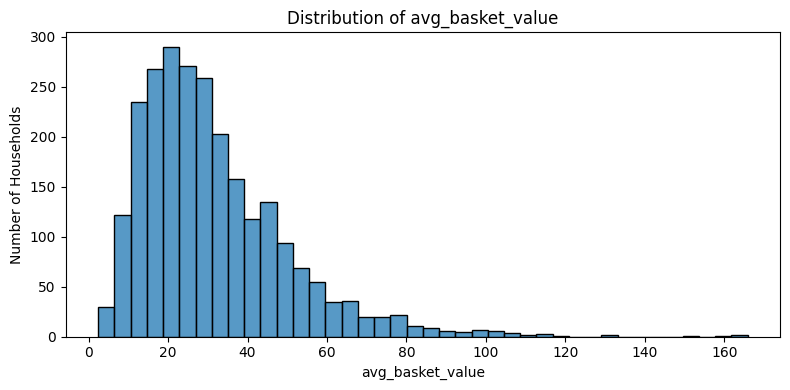

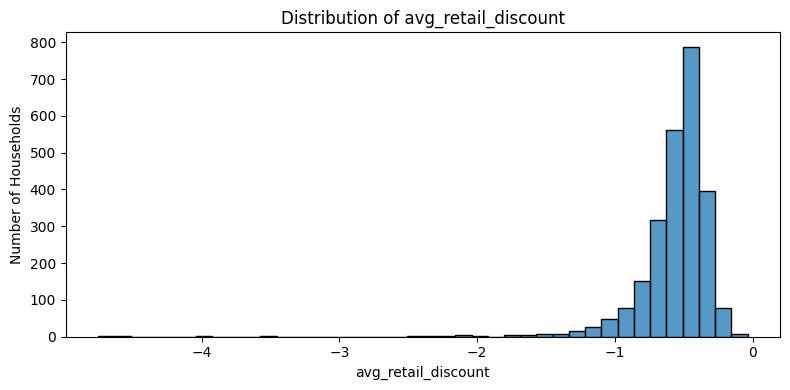

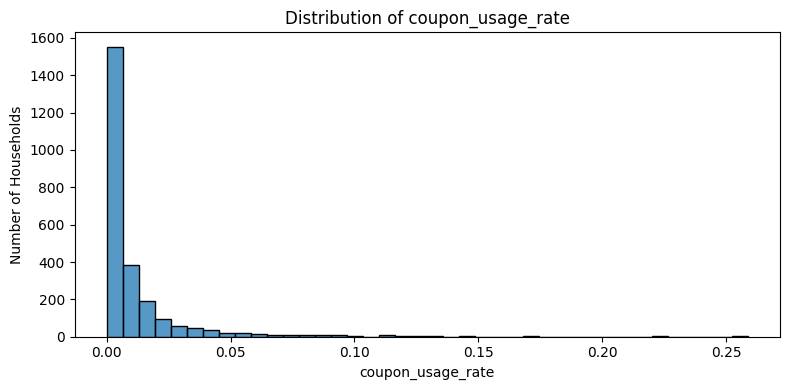

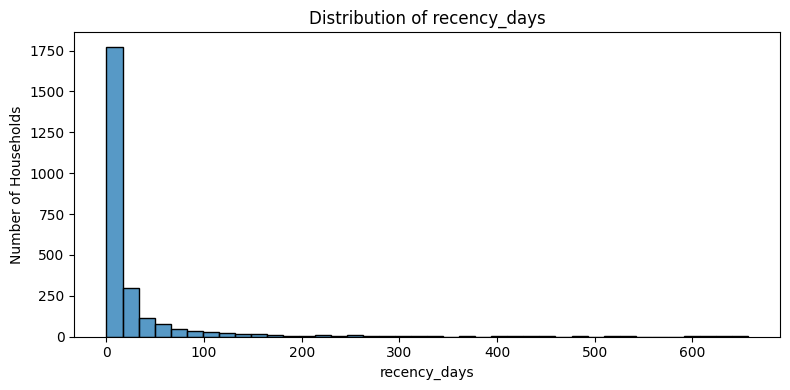

In [14]:
for col in behavior_cols:
    plt.figure(figsize=(8, 4))
    
    sns.histplot(
        data=household_eda,
        x=col,
        bins=40
    )
    
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Households")
    plt.tight_layout()
    plt.show()

### 4.1.3. Categorical Feature Analysis

In [15]:
categorical_cols = [
    "age_desc",
    "marital_status_code",
    "income_desc",
    "homeowner_desc",
    "hh_comp_desc",
    "household_size_desc",
    "kid_category_desc"
]

In [16]:
for col in categorical_cols:
    print("=" * 60)
    print(col)
    print("=" * 60)

    summary = pd.DataFrame({
        'count': customer_df[col].value_counts(dropna=False),
        'percentage': (customer_df[col].value_counts(normalize=True, dropna=False).mul(100).round(2))
    })

    print(summary)
    print()

age_desc
          count  percentage
age_desc                   
None       1699       67.96
45-54       288       11.52
35-44       194        7.76
25-34       142        5.68
65+          72        2.88
55-64        59        2.36
19-24        46        1.84

marital_status_code
                     count  percentage
marital_status_code                   
None                  1699       67.96
U                      344       13.76
A                      340       13.60
B                      117        4.68

income_desc
             count  percentage
income_desc                   
None          1699       67.96
50-74K         192        7.68
35-49K         172        6.88
75-99K          96        3.84
25-34K          77        3.08
15-24K          74        2.96
Under 15K       61        2.44
125-149K        38        1.52
100-124K        34        1.36
150-174K        30        1.20
250K+           11        0.44
175-199K        11        0.44
200-249K         5        0.20

homeo

#### Key observations

- Household behavioral variables are generally right-skewed, with a small number of highly active/high-spending households.
- `total_units_purchased` shows particularly strong skewness and a very long upper tail.
- `total_spend`, `total_baskets`, `active_days`, and `unique_products` also show substantial right-skewness.
- Most households have very low coupon usage rates.
- Most households have relatively recent activity, although `recency_days` has a long upper tail.
- Demographic information is missing for 1,699 of 2,500 households (67.96%), so demographic analyses should be interpreted using only households with available demographic information.
- The demographic categories observed among the available records are unevenly distributed, with `45-54` being the largest observed age group, `50-74K` the largest income band, and `Homeowner` the largest homeowner category.

## 4.2 Customer Spending & Purchase Behavior

### 4.2.1. Household Spending Distribution

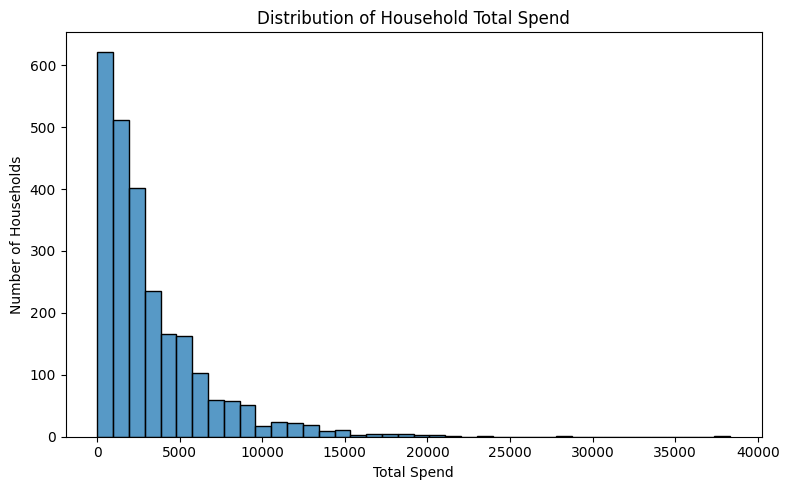

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=household_eda,
    x="total_spend",
    bins=40
)

plt.title("Distribution of Household Total Spend")
plt.xlabel("Total Spend")
plt.ylabel("Number of Households")
plt.tight_layout()
plt.show()

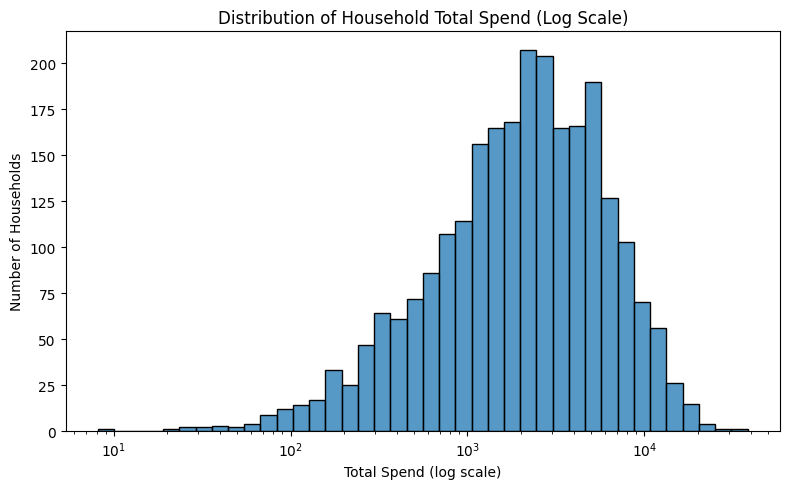

In [18]:
# Log-scale view of household spending distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=household_eda,
    x="total_spend",
    bins=40,
    log_scale=True
)

plt.title("Distribution of Household Total Spend (Log Scale)")
plt.xlabel("Total Spend (log scale)")
plt.ylabel("Number of Households")
plt.tight_layout()
plt.show()

### 4.2.2. Purchase Frequency vs. Total Spending

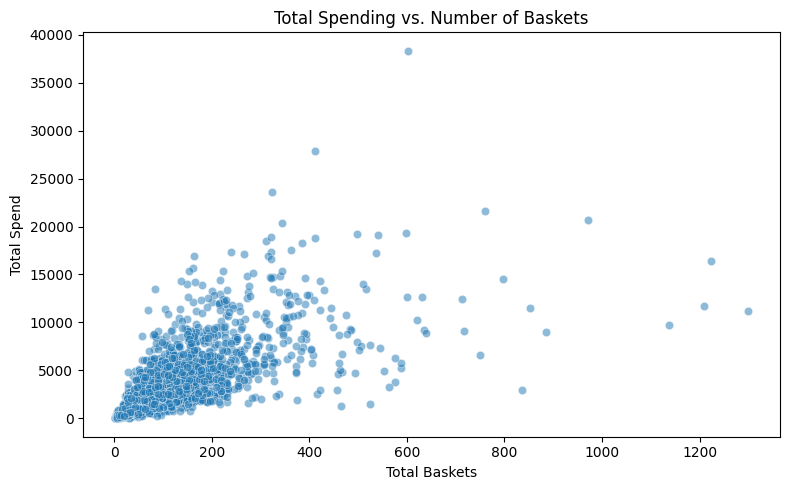

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=household_eda,
    x="total_baskets",
    y="total_spend",
    alpha=0.5
)

plt.title("Total Spending vs. Number of Baskets")
plt.xlabel("Total Baskets")
plt.ylabel("Total Spend")
plt.tight_layout()
plt.show()

In [20]:
correlation = household_eda["total_baskets"].corr(
    household_eda["total_spend"]
)

print(f"Correlation between total baskets and total spend: {correlation:.3f}")

Correlation between total baskets and total spend: 0.703


### 4.2.3. Distribution of Average Basket Value

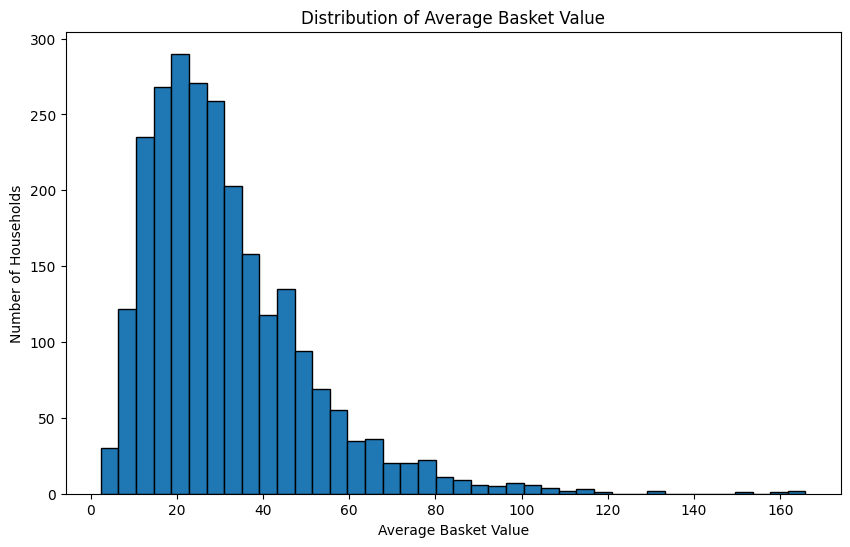

In [21]:
plt.figure(figsize=(10, 6))

plt.hist(
    household_eda["avg_basket_value"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Average Basket Value")
plt.xlabel("Average Basket Value")
plt.ylabel("Number of Households")

plt.show()

### 4.2.4 Average Basket Value vs. Total Baskets

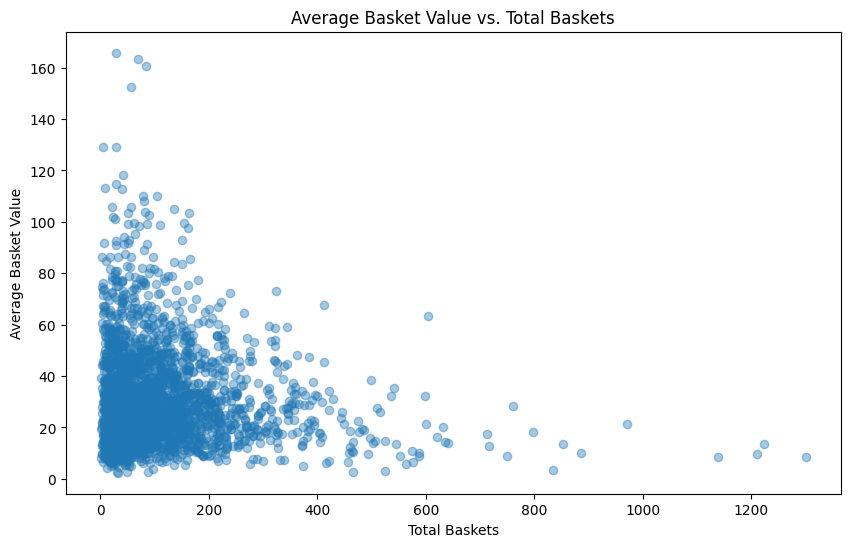

Correlation between total baskets and average basket value: -0.124


In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    data=household_eda,
    x="total_baskets",
    y="avg_basket_value",
    alpha=0.4
)

plt.title("Average Basket Value vs. Total Baskets")
plt.xlabel("Total Baskets")
plt.ylabel("Average Basket Value")

plt.show()

# Correlation between Total Baskets and Average Basket Value
correlation = customer_df[
    ["total_baskets", "avg_basket_value"]
].corr().iloc[0, 1]

print(f"Correlation between total baskets and average basket value: {correlation:.3f}")

### 4.2.5. Distribution of Total Units Purchased

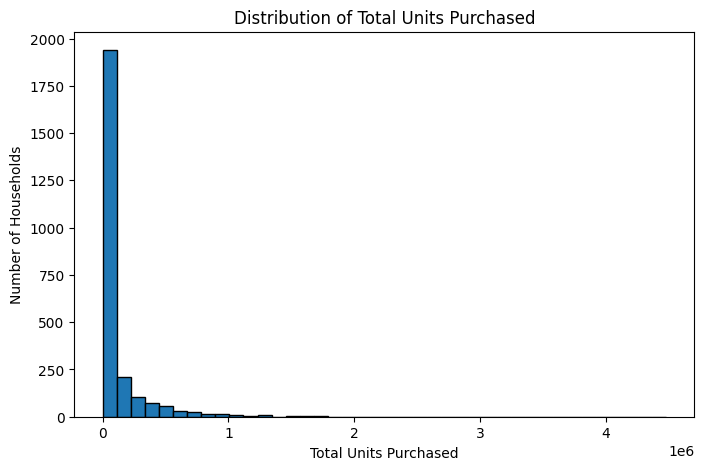

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(
    customer_df["total_units_purchased"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Total Units Purchased")
plt.xlabel("Total Units Purchased")
plt.ylabel("Number of Households")

plt.show()

* The vast majority of households purchased a relatively small number of units.
* A small number of households have extremely high purchase volumes, producing a very long right tail.
* The maximum is around 4.48 million units, compared with a median of only 11,084.5 units.
* Because of this extreme skew, the raw histogram compresses most households into the leftmost region.

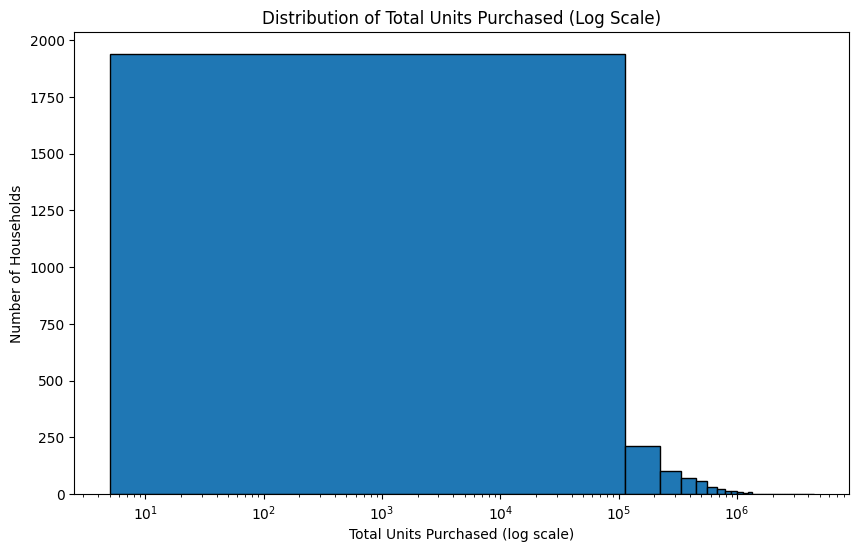

In [24]:
# Log-Scale Distribution of Total Units Purchased

plt.figure(figsize=(10, 6))

plt.hist(
    customer_df["total_units_purchased"],
    bins=40,
    edgecolor="black"
)

plt.xscale("log")

plt.title("Distribution of Total Units Purchased (Log Scale)")
plt.xlabel("Total Units Purchased (log scale)")
plt.ylabel("Number of Households")

plt.show()

Due to the strong right-skewness of total_units_purchased, plotting a histogram with a logarithmic x-axis and maintaining bins based on the linear scale means that most observations are concentrated in the first bin. This is why the very large, solid block appears.

To conduct EDA, a log transformation of the variable is needed before plotting.

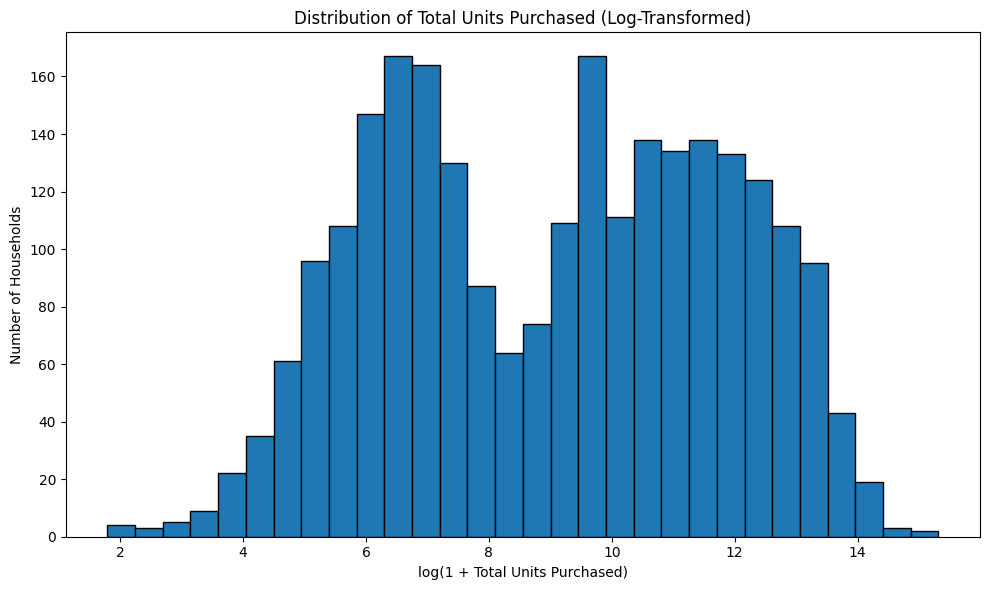

In [25]:
# Log-transformed Distribution of Total Units Purchased

log_units = np.log1p(household_eda["total_units_purchased"])

plt.figure(figsize=(10, 6))

plt.hist(log_units, bins=30, edgecolor="black")

plt.title("Distribution of Total Units Purchased (Log-Transformed)")
plt.xlabel("log(1 + Total Units Purchased)")
plt.ylabel("Number of Households")

plt.tight_layout()
plt.show()

### 4.2.6. Total Units Purchased vs. Total Baskets

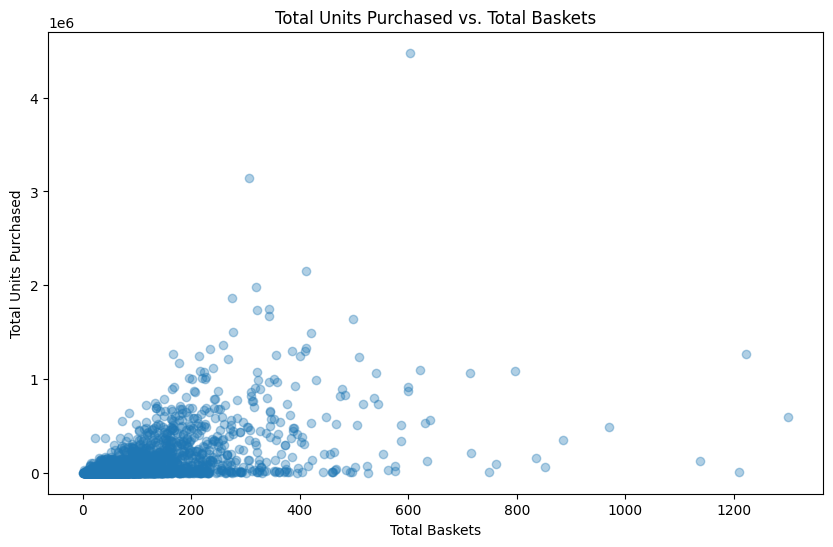

Correlation between total baskets and total units purchased: 0.496


In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    household_eda["total_baskets"],
    household_eda["total_units_purchased"],
    alpha=0.35
)

plt.xlabel("Total Baskets")
plt.ylabel("Total Units Purchased")
plt.title("Total Units Purchased vs. Total Baskets")

plt.show()

correlation = household_eda[
    ["total_baskets", "total_units_purchased"]
].corr().loc["total_baskets", "total_units_purchased"]

print(f"Correlation between total baskets and total units purchased: {correlation:.3f}")

* The correlation is 0.496, indicating a moderate positive relationship between the number of baskets and total units purchased.
* Households with more baskets generally tend to purchase more units, but the relationship is not especially strong.
* The wide vertical spread at similar basket counts indicates that basket frequency alone does not explain purchase volume.
* There are several extreme high-unit households, so the relationship is affected by substantial outliers.

### 4.2.7. Total Units Purchased vs. Total Spend

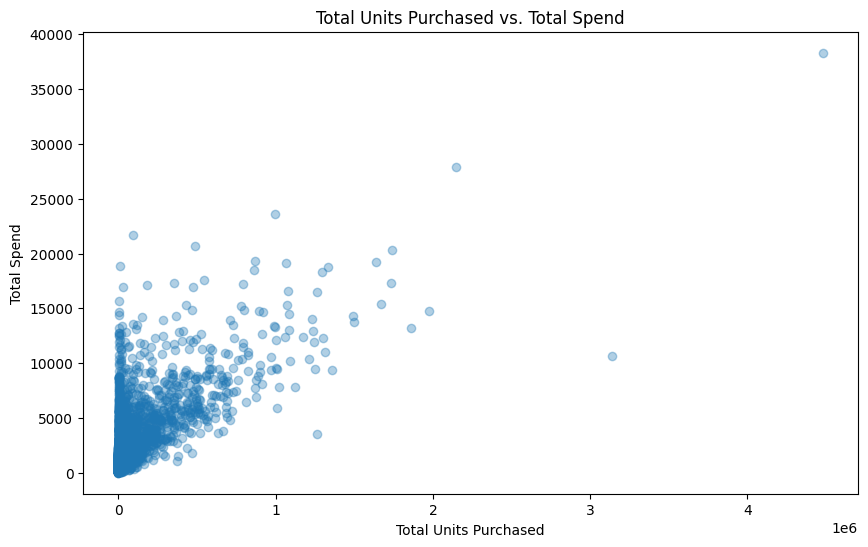

Correlation between total units purchased and total spend: 0.666


In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(
    household_eda["total_units_purchased"],
    household_eda["total_spend"],
    alpha=0.35
)

plt.xlabel("Total Units Purchased")
plt.ylabel("Total Spend")
plt.title("Total Units Purchased vs. Total Spend")

plt.show()

correlation = household_eda[
    ["total_units_purchased", "total_spend"]
].corr().loc["total_units_purchased", "total_spend"]

print(f"Correlation between total units purchased and total spend: {correlation:.3f}")

* Households purchasing more units generally tend to have higher total spending.
* The relationship is clearly positive, but there is considerable variation in spending for households with similar unit volumes.
* The extreme values on both axes show that a relatively small number of households have exceptionally high purchase volumes and/or spending.
* This also reinforces the earlier finding that household purchasing behavior is highly heterogeneous.

### 4.2.8. Average Retail Discount vs. Total Spend

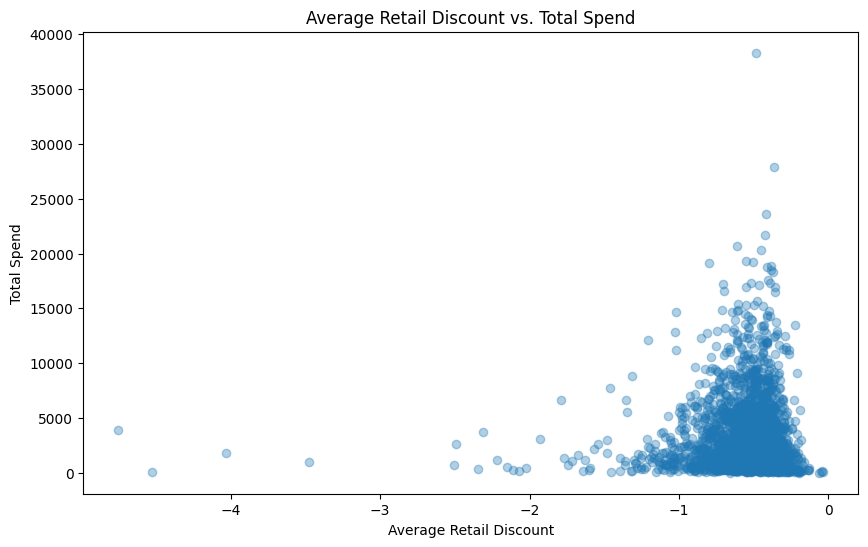

Correlation between average retail discount and total spend: 0.041


In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(
    household_eda["avg_retail_discount"],
    household_eda["total_spend"],
    alpha=0.35
)

plt.xlabel("Average Retail Discount")
plt.ylabel("Total Spend")
plt.title("Average Retail Discount vs. Total Spend")

plt.show()

correlation = household_eda[
    ["avg_retail_discount", "total_spend"]
].corr().loc["avg_retail_discount", "total_spend"]

print(f"Correlation between average retail discount and total spend: {correlation:.3f}")

The correlation is 0.041, which indicates an essentially negligible linear relationship between average retail discount and total household spending.
* The scatter plot does not show a clear linear trend between discount level and total spend.
* Most households are concentrated around average discount values between roughly -1 and 0.
* The extreme negative discount values occur for relatively few households and do not appear to correspond consistently to either high or low spending.
Therefore, total spending by itself does not appear to be strongly associated with the average retail discount at the household level.
* This is a descriptive association, not evidence that discounts have no effect on purchasing; factors such as product mix, purchase volume, and promotional activity can also affect spending.

### 4.2.9. Coupon Usage Rate vs. Total Spend

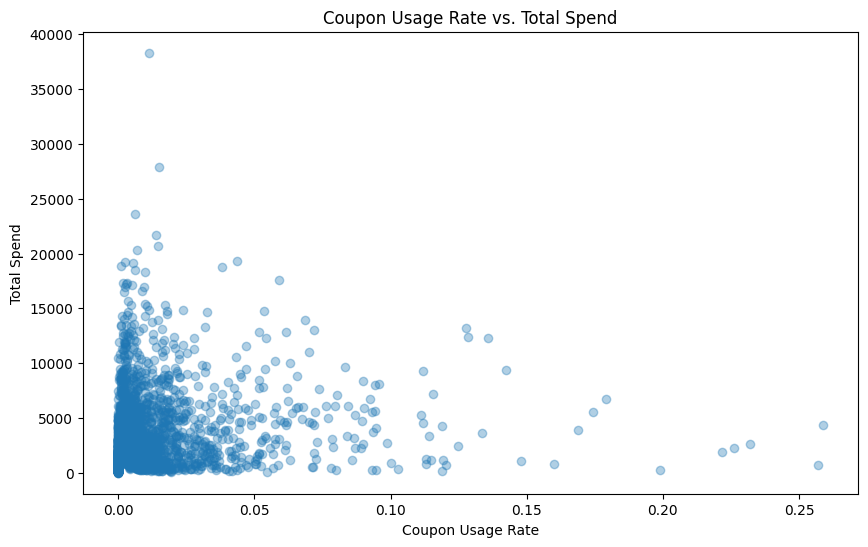

Correlation between coupon usage rate and total spend: 0.133


In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    household_eda["coupon_usage_rate"],
    household_eda["total_spend"],
    alpha=0.35
)

plt.xlabel("Coupon Usage Rate")
plt.ylabel("Total Spend")
plt.title("Coupon Usage Rate vs. Total Spend")

plt.show()

correlation = household_eda[
    ["coupon_usage_rate", "total_spend"]
].corr().loc["coupon_usage_rate", "total_spend"]

print(f"Correlation between coupon usage rate and total spend: {correlation:.3f}")

The correlation is 0.133, indicating a weak positive linear relationship between coupon usage rate and total household spending.

* Most households have a very low coupon usage rate, concentrated close to zero.
* Higher coupon usage rates are relatively uncommon.
* The wide spread in spending at low coupon usage rates shows that coupon usage alone does not explain household spending.
* The weak correlation suggests that households with higher coupon usage rates tend to have somewhat higher spending, but the association is limited.
* As with the previous relationships, this is an association rather than evidence that coupon usage causes higher spending.

## 4.3. Customer Recency & Engagement

### 4.3.1. Distribution of Active Days

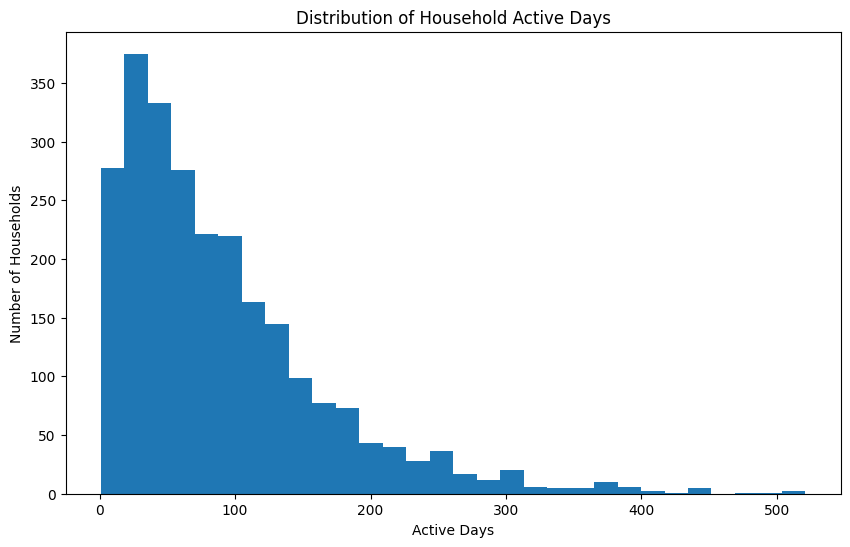

In [30]:
plt.figure(figsize=(10, 6))

plt.hist(
    household_eda["active_days"],
    bins=30
)

plt.xlabel("Active Days")
plt.ylabel("Number of Households")
plt.title("Distribution of Household Active Days")

plt.show()

* Most households have relatively low numbers of active shopping days, with the highest concentration roughly in the 20–80 day range.
* A relatively small group of households is active for 200+ days, with a few extending beyond 400 days.
* This indicates substantial variation in household engagement: some households shop relatively infrequently, while a smaller group is active across a large portion of the observation period.
* The long right tail also means the mean (90.2 days) is pulled upward by highly active households; the median (70 days) from our earlier descriptive statistics is a better representation of the typical household.

### 4.3.2. Distribution of Recency Days

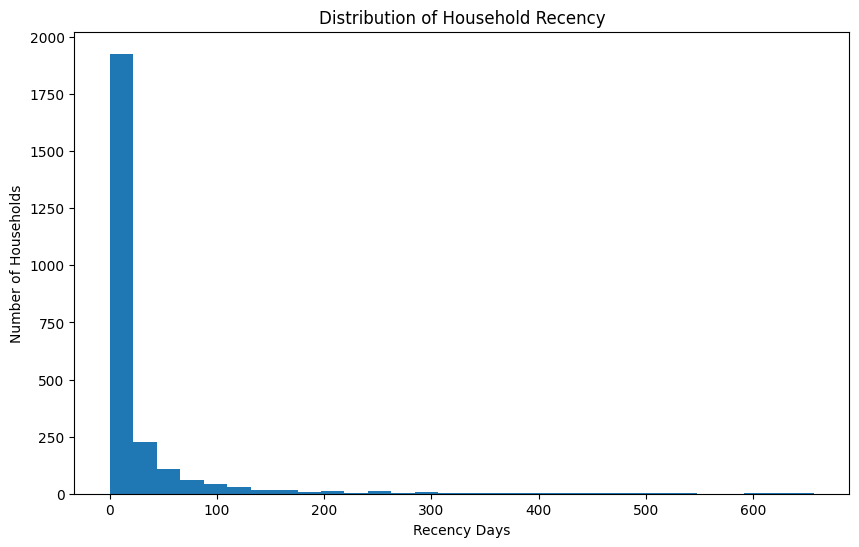

In [31]:
plt.figure(figsize=(10, 6))

plt.hist(
    household_eda["recency_days"],
    bins=30
)

plt.xlabel("Recency Days")
plt.ylabel("Number of Households")
plt.title("Distribution of Household Recency")

plt.show()

The plot shows a strongly right-skewed recency distribution: most households purchased relatively recently, while a smaller number have very large recency values.

### 4.3.3. Recency vs. Total Spending

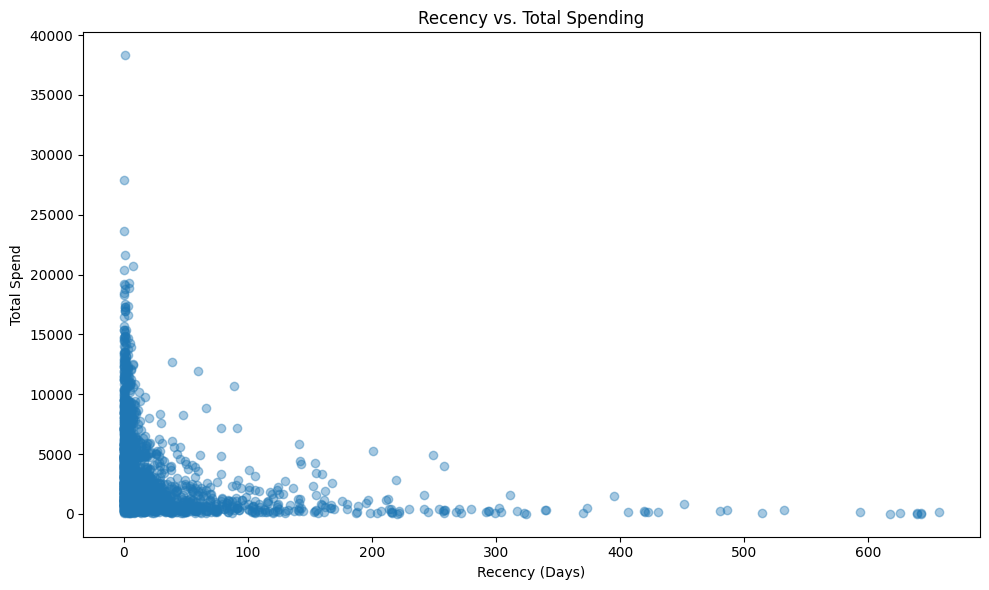

Correlation between recency and total spending: -0.239


In [32]:
plt.figure(figsize=(10, 6))

plt.scatter(
    household_eda["recency_days"],
    household_eda["total_spend"],
    alpha=0.4
)

plt.title("Recency vs. Total Spending")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Spend")

plt.tight_layout()
plt.show()

correlation = household_eda["recency_days"].corr(household_eda["total_spend"])

print(f"Correlation between recency and total spending: {correlation:.3f}")

The plot shows a strong concentration of high-spending households at low recency values, while households with larger recency values generally have much lower spending. There are also a few high-spending households with very low recency.

### 4.3.4. Purchase Frequency vs. Recency

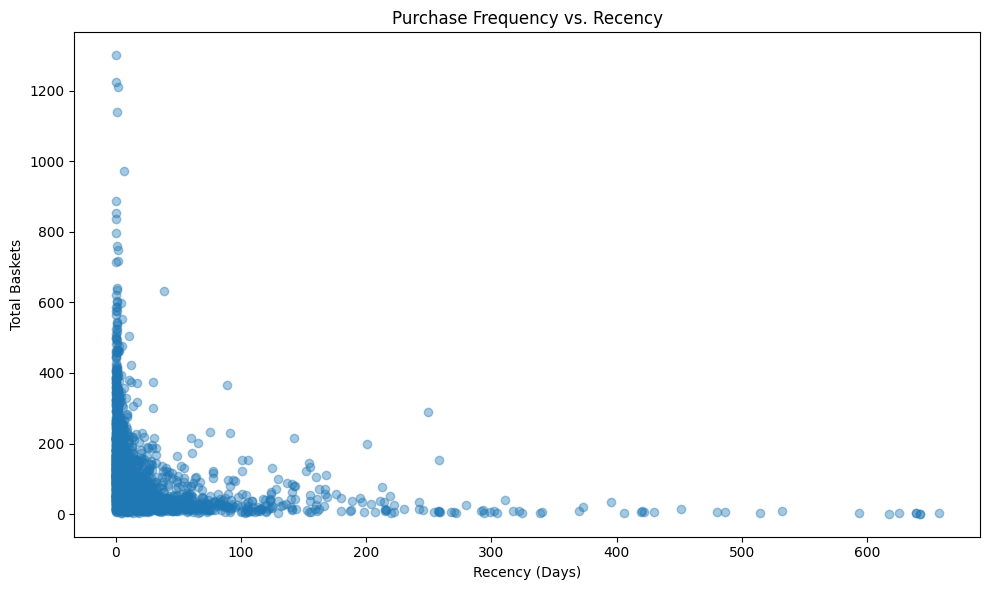

Correlation between recency and total baskets: -0.234


In [33]:
plt.figure(figsize=(10, 6))

plt.scatter(
    household_eda["recency_days"],
    household_eda["total_baskets"],
    alpha=0.4
)

plt.title("Purchase Frequency vs. Recency")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Baskets")

plt.tight_layout()
plt.show()

correlation = household_eda["recency_days"].corr(household_eda["total_baskets"])

print(f"Correlation between recency and total baskets: {correlation:.3f}")

The correlation is -0.234, indicating a modest negative relationship between recency and purchase frequency. This means that as recency values (days since last purchase) increase, purchase frequency tends to decrease, although the relationship is not especially strong.

## 4.4. Customer Segmentation Patterns

### 4.4.1. RFM Feature Distributions

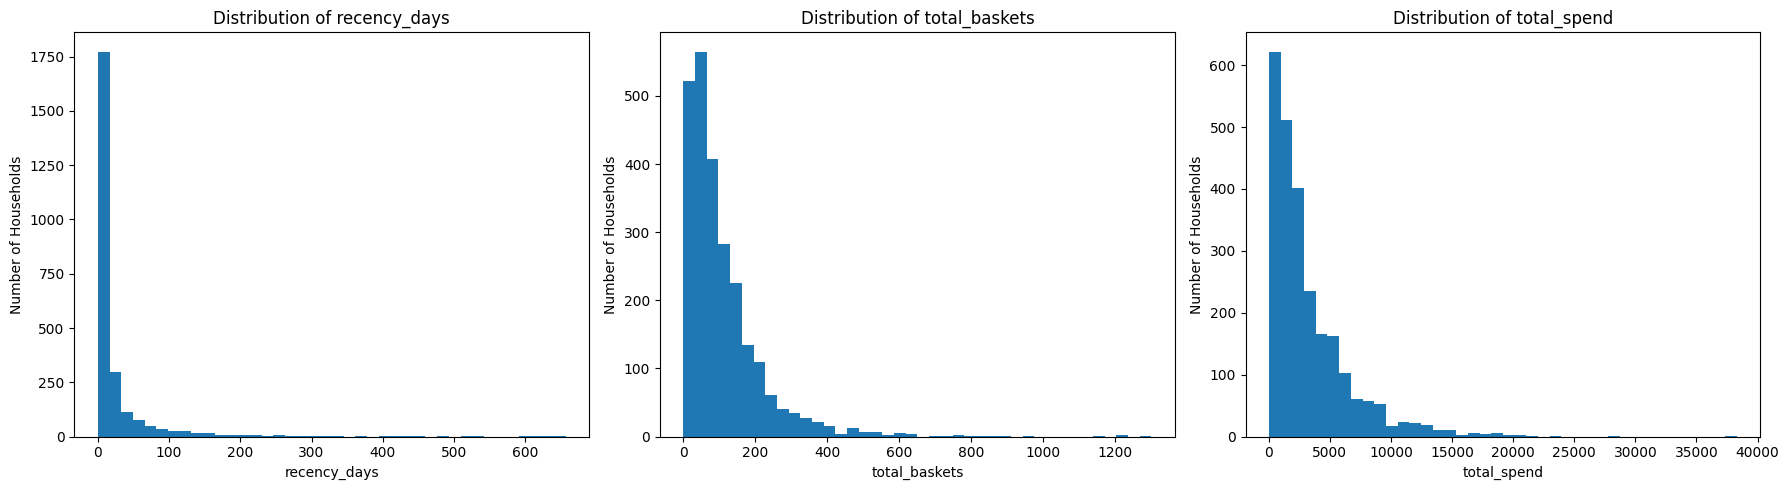

In [34]:
rfm_features = [
    "recency_days",
    "total_baskets",
    "total_spend"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, rfm_features):
    ax.hist(
        household_eda[feature].dropna(),
        bins=40
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Households")

plt.tight_layout()
plt.show()

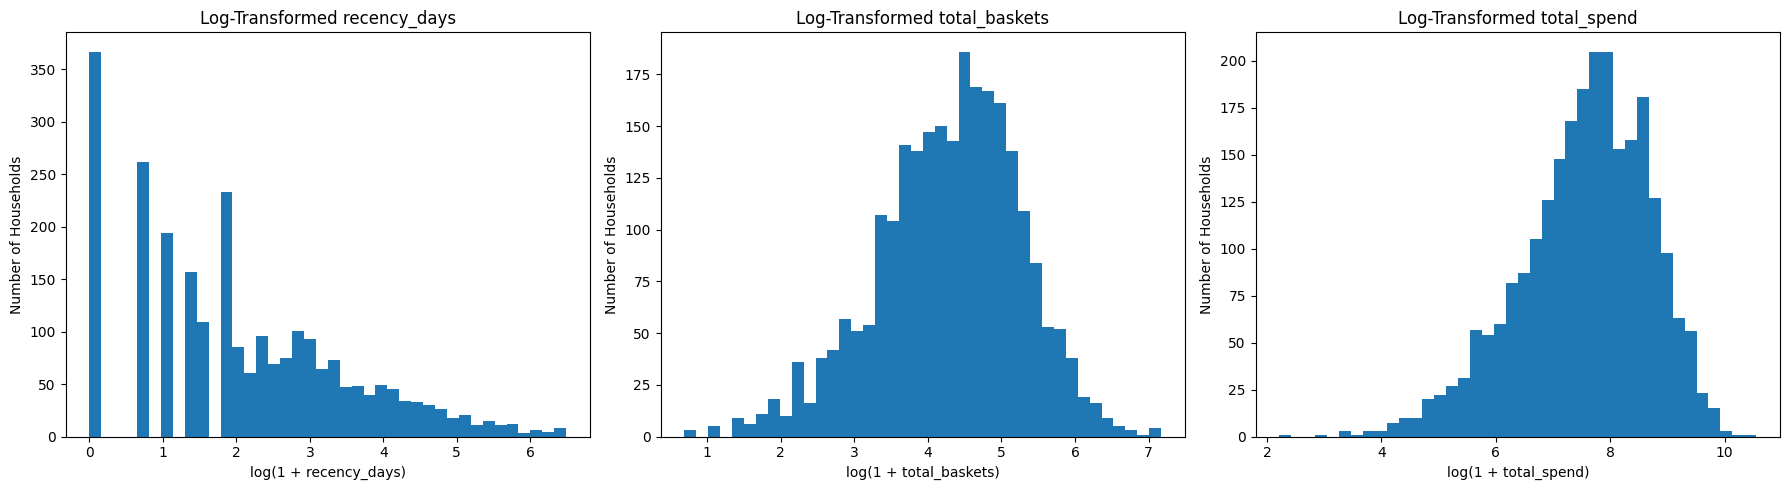

In [35]:
# Log Transformation of RFM Features
rfm = household_eda[
    ["recency_days", "total_baskets", "total_spend"]
].copy()

rfm_log = np.log1p(rfm)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, rfm_log.columns):
    ax.hist(
        rfm_log[feature].dropna(),
        bins=40
    )
    ax.set_title(f"Log-Transformed {feature}")
    ax.set_xlabel(f"log(1 + {feature})")
    ax.set_ylabel("Number of Households")

plt.tight_layout()
plt.show()

The log transformation has substantially reduced the extreme skew in total_baskets and total_spend. recency_days remains somewhat irregular because recency is naturally concentrated around certain integer day values, but the extreme right tail has been compressed.

In [36]:
# RFM Feature Correlation Analysis
rfm_correlation = rfm_log.corr()

print("Correlation Matrix of Log-Transformed RFM Features:")
print(rfm_correlation.round(3))

Correlation Matrix of Log-Transformed RFM Features:
               recency_days  total_baskets  total_spend
recency_days          1.000         -0.572       -0.525
total_baskets        -0.572          1.000        0.856
total_spend          -0.525          0.856        1.000


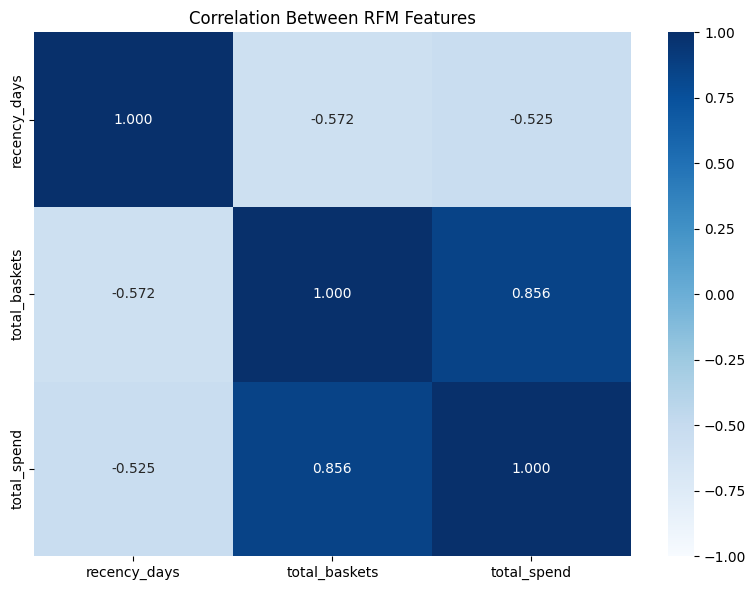

In [37]:
# RFM Correlation Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    rfm_correlation,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between RFM Features")
plt.tight_layout()
plt.show()

* Total baskets ↔ total spend: 0.856 — very strong positive relationship. Households making more purchases tend to have substantially higher spending.
* Recency ↔ total baskets: -0.572 — moderate negative relationship. Higher recency (less recent purchasing) is associated with fewer baskets.
* Recency ↔ total spend: -0.525 — moderate negative relationship. Less-recent households tend to have lower total spending.
* Using the log-transformed features makes these relationships less dominated by the extreme outliers we saw earlier.

In [38]:
# RFM Quartile-Based Behavioral Profiles

rfm_profile = household_eda[
    ["recency_days", "total_baskets", "total_spend"]
].copy()

rfm_profile["recency_quartile"] = pd.qcut(
    rfm_profile["recency_days"],
    4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

rfm_profile["frequency_quartile"] = pd.qcut(
    rfm_profile["total_baskets"],
    4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

rfm_profile["monetary_quartile"] = pd.qcut(
    rfm_profile["total_spend"],
    4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

print("Recency Quartile Distribution:")
print(rfm_profile["recency_quartile"].value_counts().sort_index())

print("\nFrequency Quartile Distribution:")
print(rfm_profile["frequency_quartile"].value_counts().sort_index())

print("\nMonetary Quartile Distribution:")
print(rfm_profile["monetary_quartile"].value_counts().sort_index())

Recency Quartile Distribution:
recency_quartile
Q1    629
Q2    693
Q3    580
Q4    598
Name: count, dtype: int64

Frequency Quartile Distribution:
frequency_quartile
Q1    641
Q2    620
Q3    614
Q4    625
Name: count, dtype: int64

Monetary Quartile Distribution:
monetary_quartile
Q1    625
Q2    625
Q3    625
Q4    625
Name: count, dtype: int64


### 4.4.2. Behavioral Patterns Across Recency Quartiles

In [39]:
recency_profile = (
    rfm_profile
    .groupby("recency_quartile", observed=True)
    [["total_baskets", "total_spend"]]
    .agg(["mean", "median"])
    .round(2)
)

print(recency_profile)

                 total_baskets        total_spend         
                          mean median        mean   median
recency_quartile                                          
Q1                      180.91  139.0     5008.91  3799.80
Q2                      124.89  103.0     3826.31  2961.83
Q3                       80.87   62.0     2474.36  1826.10
Q4                       48.90   32.0     1371.40   806.08


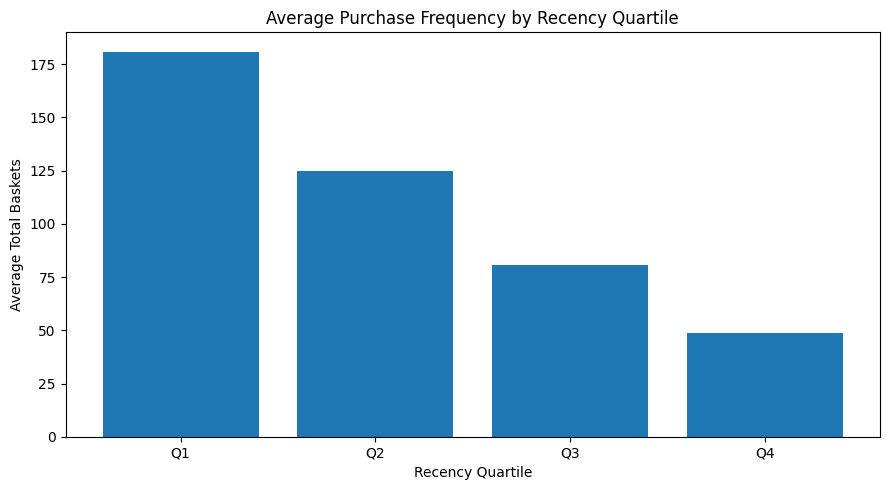

In [40]:
# Average Purchase Frequency by Recency Quartile

recency_frequency = (
    rfm_profile
    .groupby("recency_quartile", observed=True)["total_baskets"]
    .mean()
)

plt.figure(figsize=(9, 5))

plt.bar(
    recency_frequency.index.astype(str),
    recency_frequency.values
)

plt.title("Average Purchase Frequency by Recency Quartile")
plt.xlabel("Recency Quartile")
plt.ylabel("Average Total Baskets")

plt.tight_layout()
plt.show()

More recently active households also tend to have made purchases more frequently, while households with longer periods since their last purchase have substantially lower purchase frequency.

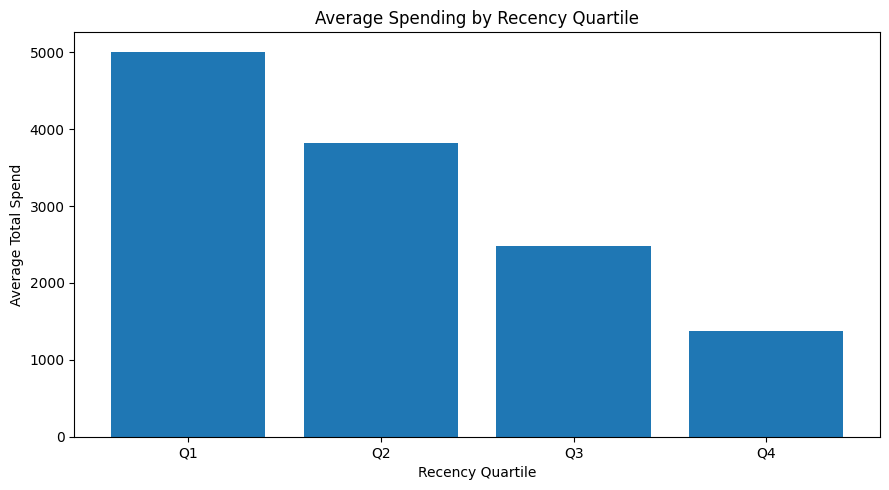

In [41]:
# Average Spending by Recency Quartile

recency_spending = (
    rfm_profile
    .groupby("recency_quartile", observed=True)["total_spend"]
    .mean()
)

plt.figure(figsize=(9, 5))

plt.bar(
    recency_spending.index.astype(str),
    recency_spending.values
)

plt.title("Average Spending by Recency Quartile")
plt.xlabel("Recency Quartile")
plt.ylabel("Average Total Spend")

plt.tight_layout()
plt.show()

Households that purchased more recently tend to have substantially higher historical spending. Average spending falls consistently as recency increases.

C:\Users\JITEN\AppData\Local\Temp\ipykernel_22664\2796455018.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  rf_spend = rfm_profile.pivot_table(


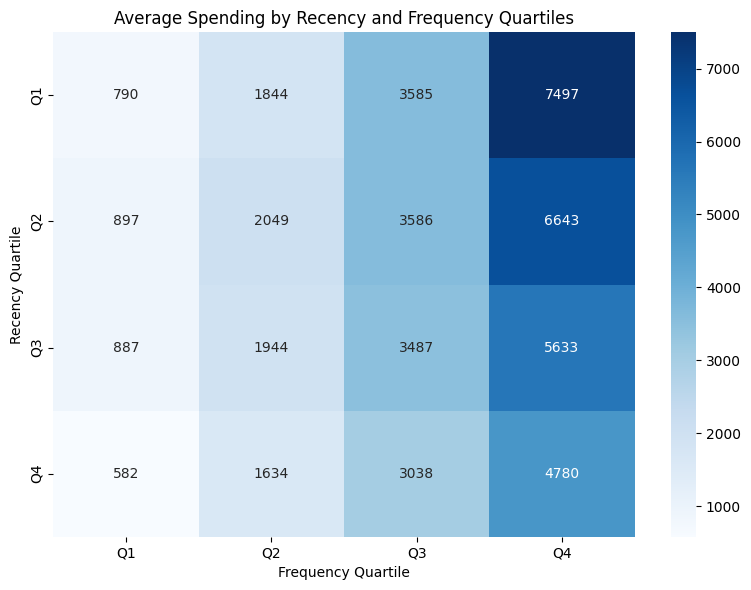

In [42]:
# Average spending by Recency and Frequency quartiles

rf_spend = rfm_profile.pivot_table(
    values='total_spend',
    index='recency_quartile',
    columns='frequency_quartile',
    aggfunc='mean'
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    rf_spend,
    annot=True,
    fmt='.0f',
    cmap='Blues'
)

plt.title('Average Spending by Recency and Frequency Quartiles')
plt.xlabel('Frequency Quartile')
plt.ylabel('Recency Quartile')
plt.tight_layout()
plt.show()

* Frequency shows a strong positive relationship with spending. Average spending increases consistently from Frequency Q1 → Q4 across every recency quartile.
* For the most recent households (Recency Q1), average spending rises from 790 at Frequency Q1 to 7,497 at Frequency Q4.
* Recency also differentiates spending: within each frequency quartile, the more recent groups generally have higher average spending.
* The highest-spending combination is Recency Q1 + Frequency Q4: 7,497.
* The lowest is Recency Q4 + Frequency Q1: 582.
* Overall, the heatmap indicates that high purchase frequency is particularly strongly associated with high household spending, while recency provides an additional separation.

C:\Users\JITEN\AppData\Local\Temp\ipykernel_22664\3945422499.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  rm_frequency = rfm_profile.pivot_table(


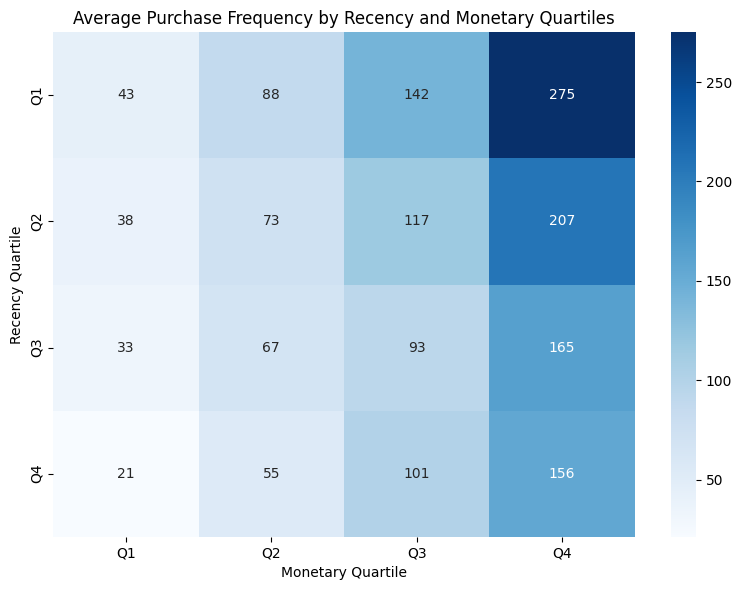

In [43]:
# Average purchase frequency by Recency and Monetary quartiles

rm_frequency = rfm_profile.pivot_table(
    values='total_baskets',
    index='recency_quartile',
    columns='monetary_quartile',
    aggfunc='mean'
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    rm_frequency,
    annot=True,
    fmt='.0f',
    cmap='Blues'
)

plt.title('Average Purchase Frequency by Recency and Monetary Quartiles')
plt.xlabel('Monetary Quartile')
plt.ylabel('Recency Quartile')
plt.tight_layout()
plt.show()

* Monetary quartile has a strong positive relationship with purchase frequency. Average frequency increases consistently from Monetary Q1 → Q4 within every recency quartile.
* For the most recent households (Recency Q1), average frequency rises from 43 baskets at Monetary Q1 to 275 baskets at Monetary Q4.
* Recency also matters: within every monetary quartile, the more recent groups generally have higher purchase frequency.
* The highest-frequency combination is Recency Q1 + Monetary Q4: 275 baskets.
* The lowest is Recency Q4 + Monetary Q1: 21 baskets.
* The pattern is highly consistent across the heatmap, showing that higher-spending households also tend to have higher purchase frequency, with recency providing an additional behavioral distinction.

## 4.5. Demographic Patterns

### 4.5.1. Demographic Distribution

In [44]:
demographic_cols = [
    'age_desc',
    'marital_status_code',
    'income_desc',
    'household_size_desc',
    'kid_category_desc'
]

for col in demographic_cols:
    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")
    print(household_eda[col].value_counts(dropna=False))


age_desc
age_desc
None     1699
45-54     288
35-44     194
25-34     142
65+        72
55-64      59
19-24      46
Name: count, dtype: int64

marital_status_code
marital_status_code
None    1699
U        344
A        340
B        117
Name: count, dtype: int64

income_desc
income_desc
None         1699
50-74K        192
35-49K        172
75-99K         96
25-34K         77
15-24K         74
Under 15K      61
125-149K       38
100-124K       34
150-174K       30
250K+          11
175-199K       11
200-249K        5
Name: count, dtype: int64

household_size_desc
household_size_desc
None    1699
2        318
1        255
3        109
5+        66
4         53
Name: count, dtype: int64

kid_category_desc
kid_category_desc
None            1699
None/Unknown     558
1                114
3+                69
2                 60
Name: count, dtype: int64


- Only 801 / 2,500 households (32.04%) have demographic information. Therefore, demographic-behavior analyses will use 801 households, not all 2,500.
- None here represents missing demographic information.
- None/Unknown under kid_category_desc is a recorded category, so we should distinguish it from missing values.

### 4.5.2 Demographics vs. Customer Spending

In [45]:
# Spending by age group

age_spend = (
    household_eda.dropna(subset=['age_desc']).groupby('age_desc')['total_spend'].agg(
        households='count',
        median_spend='median',
        mean_spend='mean'
    ).sort_values('median_spend', ascending=False)
)

age_spend

,households,median_spend,mean_spend
age_desc,,,
35-44,194,5494.275,6402.818505
25-34,142,4736.025,5478.424296
45-54,288,4713.040,5755.093924
55-64,59,4209.350,5054.729153
19-24,46,4018.895,4708.326522
65+,72,3551.520,4241.029583


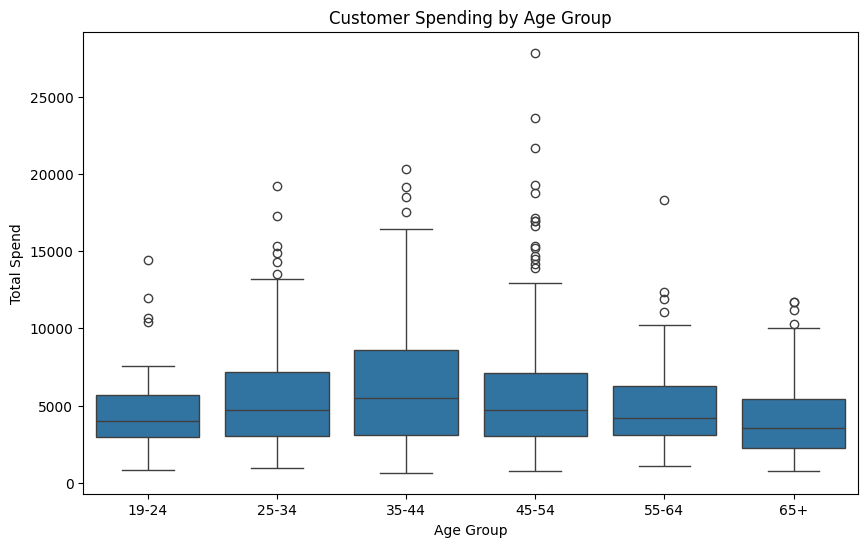

In [46]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=household_eda.dropna(subset=['age_desc']),
    x='age_desc',
    y='total_spend',
    order=['19-24', '25-34', '35-44', '45-54', '55-64', '65+']
)

plt.title('Customer Spending by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Spend')
plt.show()

- The 35–44 age group has the highest median spending at approximately 5,494.
- The 65+ group has the lowest median spending at approximately 3,552.
- The 25–34 and 45–54 groups have very similar median spending (~4,700).
- Spending distributions are right-skewed across the age groups, with numerous high-spending outliers.
- The relationship is not simply linear with age: spending rises toward the 35–44 group and then generally declines among older groups.

In [47]:
# Spending by income group
income_spend = (
    household_eda.dropna(subset=['income_desc']).groupby('income_desc')['total_spend'].agg(
        households='count',
        median_spend='median',
        mean_spend='mean'
    )
)

income_spend

,households,median_spend,mean_spend
income_desc,,,
100-124K,34,5949.72,5927.740294
125-149K,38,6004.79,7912.055263
15-24K,74,3549.88,4097.124324
150-174K,30,8437.10,8394.840667
175-199K,11,6644.85,8548.462727
200-249K,5,5399.64,5726.486000
25-34K,77,4405.47,4938.069870
250K+,11,11938.20,10789.900000
35-49K,172,3895.15,4802.008547


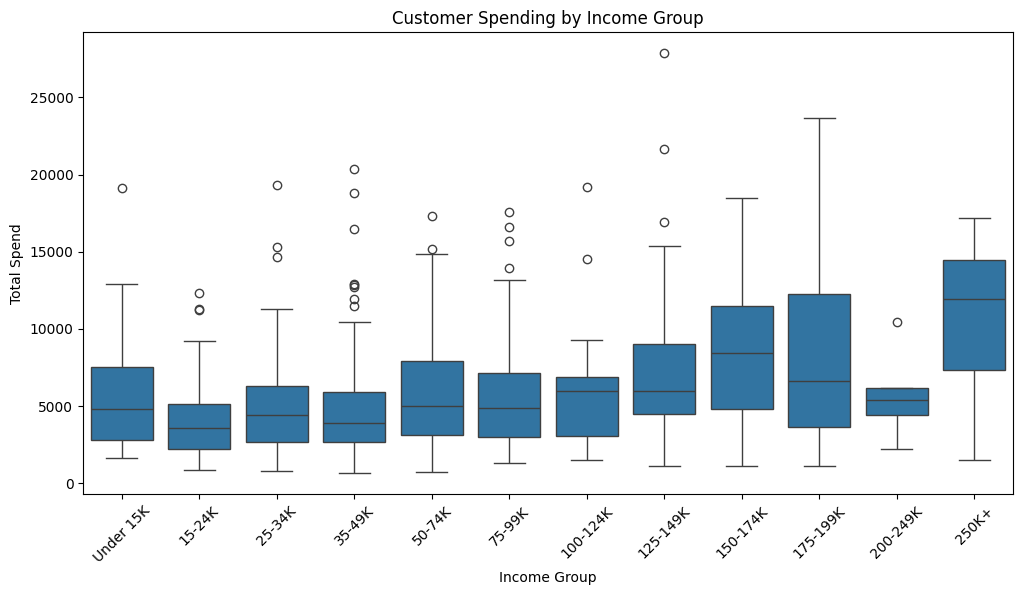

In [48]:
income_order = [
    'Under 15K',
    '15-24K',
    '25-34K',
    '35-49K',
    '50-74K',
    '75-99K',
    '100-124K',
    '125-149K',
    '150-174K',
    '175-199K',
    '200-249K',
    '250K+'
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=household_eda.dropna(subset=['income_desc']),
    x='income_desc',
    y='total_spend',
    order=income_order
)

plt.title('Customer Spending by Income Group')
plt.xlabel('Income Group')
plt.ylabel('Total Spend')
plt.xticks(rotation=45)
plt.show()

Higher-income households generally show higher spending, particularly in the upper-income groups, but the relationship is not perfectly monotonic and is affected by small sample sizes in some high-income categories.

In [49]:
# Spending by household size

hh_size_spend = (
    household_eda.dropna(subset=['household_size_desc']).groupby('household_size_desc')['total_spend'].agg(
        households='count',
        median_spend='median',
        mean_spend='mean'
    )
)

hh_size_spend

,households,median_spend,mean_spend
household_size_desc,,,
1,255,4430.010,5032.465255
2,318,4615.885,5538.487704
3,109,4775.560,6060.418073
4,53,5991.840,6612.912264
5+,66,5375.410,6698.918333


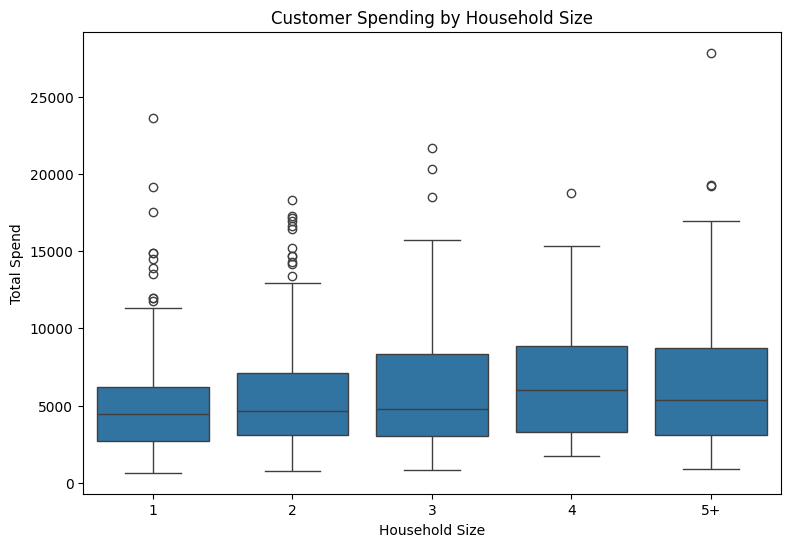

In [50]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=household_eda.dropna(subset=['household_size_desc']),
    x='household_size_desc',
    y='total_spend',
    order=['1', '2', '3', '4', '5+']
)

plt.title('Customer Spending by Household Size')
plt.xlabel('Household Size')
plt.ylabel('Total Spend')
plt.show()

- Median spending generally increases from 1-person to 4-person households.
- 4-person households have the highest median spending (~5,992).
- The 5+ category has a somewhat lower median (~5,375), so the relationship is not strictly increasing.
- Larger households also show considerable spending variation.
- The 1 and 2 person groups have the largest sample sizes, making their estimates more stable than the smaller 4 and 5+ groups.

### 4.5.3. Demographics vs. Purchase Engagement

In [51]:
# Purchase frequency by age group

age_engagement = (
    household_eda.dropna(subset=['age_desc']).groupby('age_desc')['total_baskets'].agg(
        households='count',
        median_baskets='median',
        mean_baskets='mean'
    )
)

age_engagement

,households,median_baskets,mean_baskets
age_desc,,,
19-24,46,156.5,176.717391
25-34,142,135.5,159.859155
35-44,194,147.0,188.793814
45-54,288,141.5,178.451389
55-64,59,157.0,170.457627
65+,72,124.0,158.791667


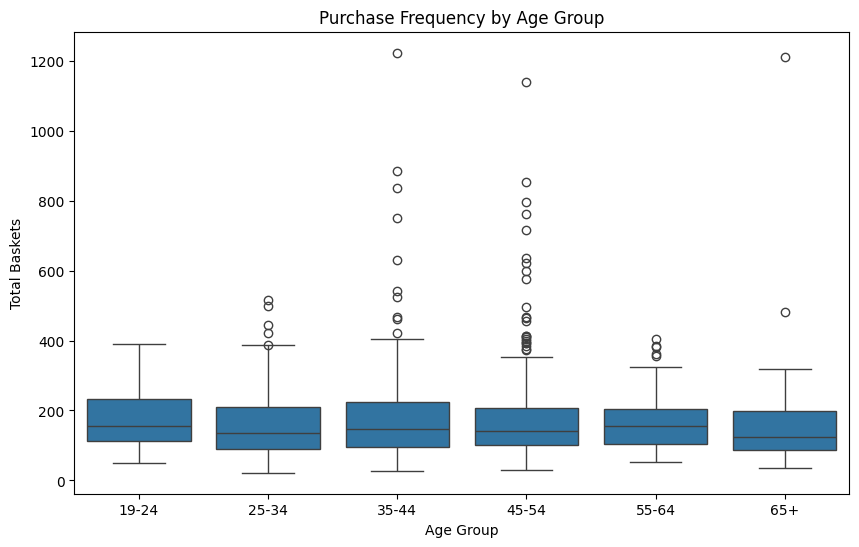

In [52]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=household_eda.dropna(subset=['age_desc']),
    x='age_desc',
    y='total_baskets',
    order=['19-24', '25-34', '35-44', '45-54', '55-64', '65+']
)

plt.title('Purchase Frequency by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Baskets')
plt.show()

- Purchase frequency is fairly similar across most age groups, with median basket counts ranging from 124 to 157.
- The 55–64 and 19–24 groups have the highest median basket counts, while the 65+ group has the lowest.
- The 35–44 group has the highest mean basket count (~189), largely reflecting several highly active households.
- The boxplot shows substantial high-frequency outliers across age groups, particularly among 35–44 and 45–54.
- Therefore, age differences in purchase frequency appear relatively modest compared with the differences observed in spending.

In [53]:
# Purchase frequency by income group

income_engagement = (
    household_eda.dropna(subset=['income_desc']).groupby('income_desc')['total_baskets'].agg(
        households='count',
        median_baskets='median',
        mean_baskets='mean'
    )
)

income_engagement

,households,median_baskets,mean_baskets
income_desc,,,
100-124K,34,155.5,186.558824
125-149K,38,153.0,201.184211
15-24K,74,146.5,164.067568
150-174K,30,148.5,165.133333
175-199K,11,113.0,190.636364
200-249K,5,122.0,114.200000
25-34K,77,137.0,197.844156
250K+,11,200.0,218.000000
35-49K,172,132.0,172.331395


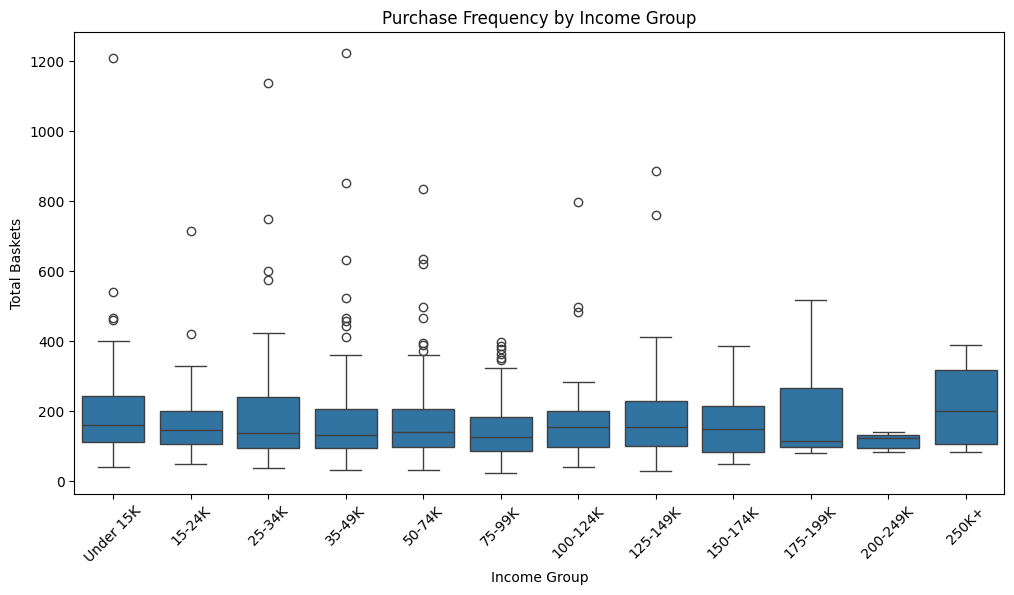

In [54]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=household_eda.dropna(subset=['income_desc']),
    x='income_desc',
    y='total_baskets',
    order=income_order
)

plt.title('Purchase Frequency by Income Group')
plt.xlabel('Income Group')
plt.ylabel('Total Baskets')
plt.xticks(rotation=45)
plt.show()

- Purchase frequency does not increase consistently with income.
- The lower-income groups actually show relatively high median basket counts: Under 15K has 159, compared with 132 for 35–49K and 124.5 for 75–99K.
- The 250K+ group has the highest median at 200, but this is based on only 11 households.
- The 200–249K and 175–199K groups also have very small samples, making their estimates unstable.
- There is substantial variation and a large number of high-frequency outliers across income groups.
- Therefore, the stronger income-related pattern we observed in spending is not reproduced in purchase frequency.

In [55]:
# Purchase frequency by household size

hh_size_engagement = (
    household_eda.dropna(subset=['household_size_desc']).groupby('household_size_desc')['total_baskets'].agg(
        households='count',
        median_baskets='median',
        mean_baskets='mean'
    )
)

hh_size_engagement

,households,median_baskets,mean_baskets
household_size_desc,,,
1,255,150.0,181.349020
2,318,136.0,169.323899
3,109,138.0,186.477064
4,53,135.0,176.849057
5+,66,130.0,159.863636


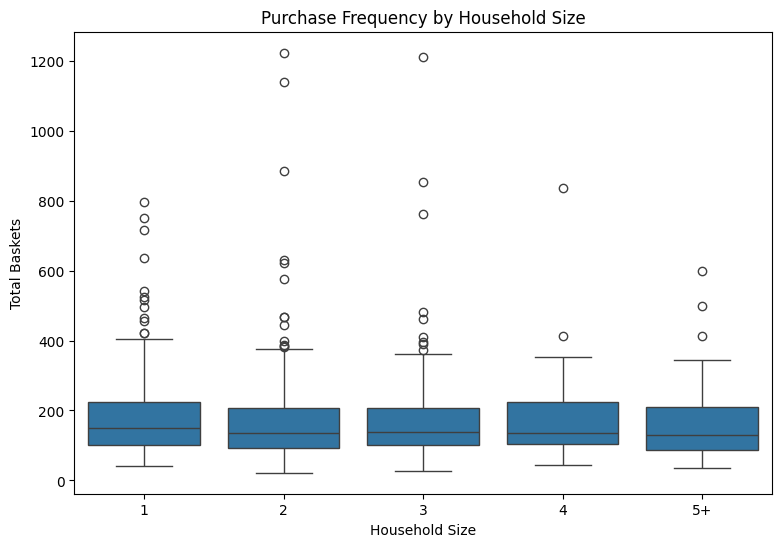

In [56]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=household_eda.dropna(subset=['household_size_desc']),
    x='household_size_desc',
    y='total_baskets',
    order=['1', '2', '3', '4', '5+']
)

plt.title('Purchase Frequency by Household Size')
plt.xlabel('Household Size')
plt.ylabel('Total Baskets')
plt.show()

- Median purchase frequency is actually highest for 1-person households (150 baskets).
- Median baskets generally decline as household size increases, from 150 for size 1 to 130 for 5+ households.
- The relationship is therefore not what we might intuitively expect—larger households do not necessarily shop more frequently.
- Mean basket counts are somewhat higher than medians because of the strong influence of highly active households and outliers.
- The boxplot confirms substantial variation within every household-size group.
- The 3-person group has a relatively high mean (~186.5) despite a median of only 138, indicating the influence of several highly active households.

### Key Finding:
Household size shows a clearer association with spending than with purchase frequency. Larger households tend to have higher spending levels, but they do not necessarily make more purchases, suggesting that differences in basket size or quantity purchased may contribute to the higher spending.

### 4.5.4. Marital Status vs. Customer Behavior

In [57]:
marital_behavior = (
    household_eda.dropna(subset=['marital_status_code']).groupby('marital_status_code').agg(
        households=('household_key', 'count'),
        median_spend=('total_spend', 'median'),
        median_baskets=('total_baskets', 'median'),
        median_units=('total_units_purchased', 'median')
    )
)

marital_behavior

,households,median_spend,median_baskets,median_units
marital_status_code,,,,
A,340,5055.855,132.0,71816.0
B,117,4526.210,133.0,50085.0
U,344,4450.500,152.0,59557.5


- Group A has the highest median spending (~ 5,056), while U has the lowest (~ 4,451).
- Purchase frequency is actually highest for U (152 baskets), despite its lower median spending.
- Groups A and B have almost identical median basket counts (132 and 133).
- This again shows that higher spending does not necessarily correspond to more shopping trips.
- Group A also has the highest median units purchased, suggesting that its higher spending is accompanied by greater purchase volume.

### 4.5.5. Household children vs. customer behavior

In [58]:
kid_behavior = (
    household_eda.dropna(subset=['kid_category_desc']).groupby('kid_category_desc').agg(
        households=('household_key', 'count'),
        median_spend=('total_spend', 'median'),
        median_baskets=('total_baskets', 'median'),
        median_units=('total_units_purchased', 'median')
    )
)

kid_behavior

,households,median_spend,median_baskets,median_units
kid_category_desc,,,,
1,114,4669.170,140.0,59509.5
2,60,6015.425,142.5,112306.5
3+,69,5519.020,131.0,55236.0
None/Unknown,558,4537.540,140.5,57140.5


- Households in the 2-children category have the highest median spending (~6,015) and by far the highest median units purchased (~112,307).
- The 3+ category has the second-highest median spending (~5,519), although its median basket frequency is lower at 131.
- Purchase frequency is relatively similar across categories, ranging from 131 to 143 baskets.
- The much higher median units for the 2-child group suggests that its higher spending may be associated more with purchase volume than substantially more frequent shopping.
- However, the None/Unknown category is large (558 households) and should not be interpreted as a child-free group. It combines households whose recorded child information is unknown/unspecified.

## 4.6 Campaign Performance & Redemption

### 4.6.1. Overall Campaign Exposure & Redemption

In [59]:
campaign_cols = customer_df.columns

In [60]:
campaign_summary = pd.DataFrame({
    'metric': [
        'Total households',
        'Households assigned at least one campaign',
        'Households redeeming at least one campaign',
        'Total campaigns assigned',
        'Total campaigns redeemed',
        'Total coupons redeemed'
    ],
    'value': [
        household_eda['household_key'].nunique(),
        (household_eda['campaigns_assigned'] > 0).sum(),
        (household_eda['campaigns_redeemed'] > 0).sum(),
        household_eda['campaigns_assigned'].sum(),
        household_eda['campaigns_redeemed'].sum(),
        household_eda['coupons_redeemed'].sum()
    ]
})

campaign_summary

,metric,value
0,Total households,2500.0
1,Households assigned at least one campaign,1584.0
2,Households redeeming at least one campaign,434.0
3,Total campaigns assigned,7208.0
4,Total campaigns redeemed,889.0
5,Total coupons redeemed,2229.0


In [61]:
# Overall campaign redemption rates

assigned_households = (household_eda['campaigns_assigned'] > 0).sum()
redeeming_households = (household_eda['campaigns_redeemed'] > 0).sum()

total_campaigns_assigned = household_eda['campaigns_assigned'].sum()
total_campaigns_redeemed = household_eda['campaigns_redeemed'].sum()

print(f"Household redemption rate: {redeeming_households / assigned_households:.2%}")

print(f"Campaign redemption rate: {total_campaigns_redeemed / total_campaigns_assigned:.2%}")

Household redemption rate: 27.40%
Campaign redemption rate: 12.33%


- 1,584 of 2,500 households (63.36%) received at least one campaign.
- 434 households redeemed at least one campaign, giving a 27.40% household-level redemption rate among campaign-exposed households.
- Across all campaign assignments, 889 of 7,208 campaigns were redeemed, corresponding to a 12.33% campaign-level redemption rate.
- The difference between the two rates is important: a household only needs to redeem one campaign to count in the household-level rate, whereas the campaign-level rate evaluates individual campaign assignments.
- There were 2,229 coupons redeemed across 889 redeemed campaigns, indicating that redeemed campaigns can involve multiple coupons.

### 4.6.2. Campaign Exposure & Redemption Distribution

In [62]:
campaign_distribution = (
    household_eda[['campaigns_assigned', 'campaigns_redeemed', 'coupons_redeemed']].describe().T
)

campaign_distribution

,count,mean,std,min,25%,50%,75%,max
campaigns_assigned,1584.0,4.550505,2.993988,1.0,2.0,4.0,6.0,17.0
campaigns_redeemed,1584.0,0.561237,1.222566,0.0,0.0,0.0,1.0,10.0
coupons_redeemed,1584.0,1.407197,3.735267,0.0,0.0,0.0,1.0,32.0


In [63]:
# Households by number of campaigns assigned

assignment_counts = (
    household_eda['campaigns_assigned'].value_counts().sort_index()
)

assignment_counts

campaigns_assigned
1.0     268
2.0     224
3.0     214
4.0     169
5.0     179
6.0     138
7.0     120
8.0      94
9.0      62
10.0     50
11.0     24
12.0     26
13.0      7
14.0      4
15.0      3
16.0      1
17.0      1
Name: count, dtype: int64

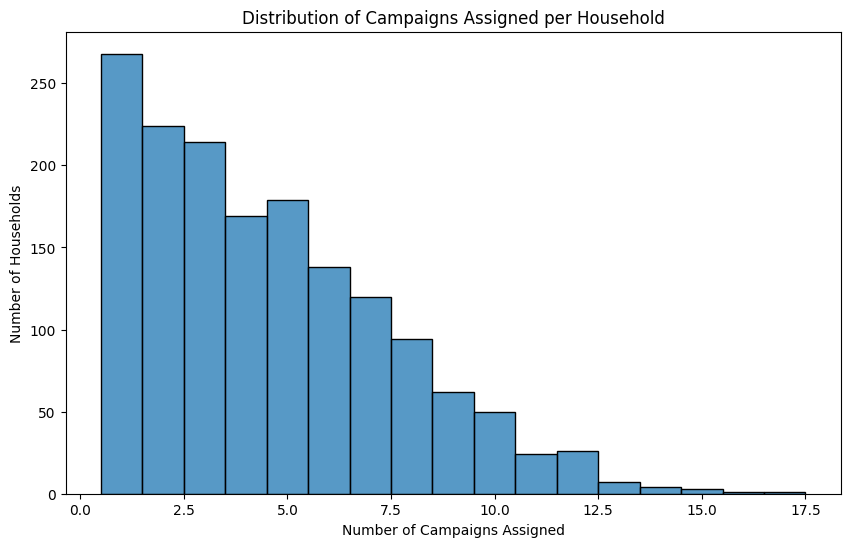

In [64]:
plt.figure(figsize=(10, 6))

sns.histplot(
    household_eda.loc[
        household_eda['campaigns_assigned'] > 0,
        'campaigns_assigned'
    ],
    discrete=True
)

plt.title('Distribution of Campaigns Assigned per Household')
plt.xlabel('Number of Campaigns Assigned')
plt.ylabel('Number of Households')
plt.show()

- 268 households (16.9%) received exactly 1 campaign.
- 706 households (44.6%) received only 1–3 campaigns.
- 1,192 households (75.3%) received 1–6 campaigns.
- Only a small number of households received more than 10 campaigns.
- The maximum exposure was 17 campaigns for a household.

So campaign exposure was not evenly distributed across households; most households received relatively few campaigns, while a smaller group experienced repeated campaign exposure.

Campaign exposure is concentrated toward a relatively small number of assignments per household, while redemption is even more concentrated, with most exposed households having zero redemptions and a smaller group accounting for multiple redemptions.

### 4.6.3. Campaign Exposure vs. Redemption

In [65]:
exposure_redemption = (
    household_eda[household_eda['campaigns_assigned'] > 0].groupby('campaigns_assigned').agg(
        households=('household_key', 'count'),
        median_redeemed=('campaigns_redeemed', 'median'),
        mean_redeemed=('campaigns_redeemed', 'mean'),
        redemption_rate=('campaigns_redeemed', lambda x: (x > 0).mean()*100)
    ).reset_index()
)

exposure_redemption

,campaigns_assigned,households,median_redeemed,mean_redeemed,redemption_rate
0,1.0,268,0.0,0.070896,7.089552
1,2.0,224,0.0,0.133929,12.053571
2,3.0,214,0.0,0.322430,21.962617
3,4.0,169,0.0,0.431953,28.402367
4,5.0,179,0.0,0.486034,27.932961
5,6.0,138,0.0,0.608696,32.608696
6,7.0,120,0.0,0.675000,37.500000
7,8.0,94,0.0,1.223404,48.936170
8,9.0,62,1.0,1.338710,51.612903
9,10.0,50,1.0,2.060000,72.000000


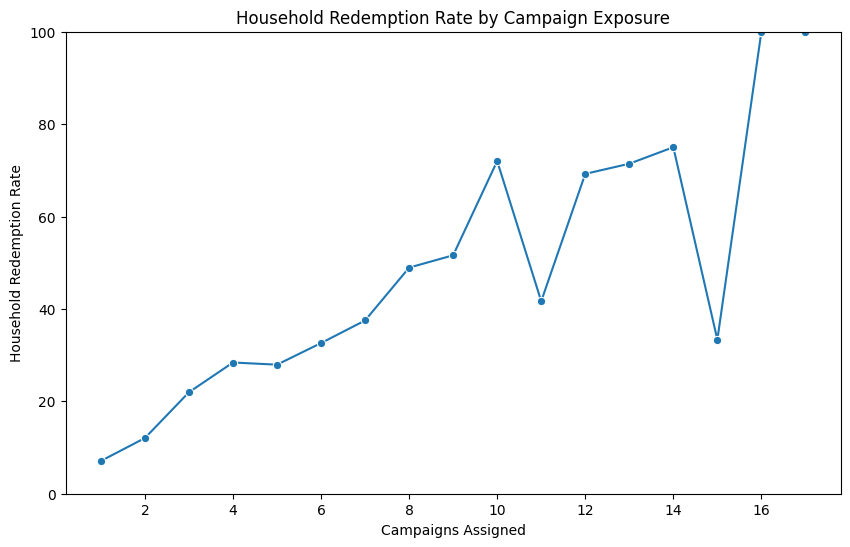

In [66]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=exposure_redemption,
    x='campaigns_assigned',
    y='redemption_rate',
    marker='o'
)

plt.title('Household Redemption Rate by Campaign Exposure')
plt.xlabel('Campaigns Assigned')
plt.ylabel('Household Redemption Rate')
plt.ylim(0, 100)
plt.show()

- Households receiving 1 campaign have a redemption rate of about 7.1%. This rises to about 22.0% for households receiving 3 campaigns. It reaches about 28.4% at 4 campaigns and 32.6% at 6 campaigns. At 8–10 assigned campaigns, the rate rises further, reaching 72.0% for the 10-campaign group.
- After that, the pattern becomes unstable because the groups are very small. For example, the 15-campaign group has only 3 households, while the 16- and 17-campaign groups each have only 1 household.
- The median number of campaigns redeemed remains 0 through several lower exposure levels, indicating that even when households receive multiple campaigns, a substantial proportion still do not redeem any.

Household redemption rates generally increase with greater campaign exposure across the lower and middle exposure levels, although the relationship becomes unstable at very high exposure levels because of small sample sizes.

## 4.7. Product-level analysis

### 4.7.1. Overall Product Sales & Reach

In [67]:
product_df[
    [
        'total_units_sold',
        'total_sales',
        'unique_households',
        'unique_baskets',
        'avg_unit_sales_value',
        'avg_retail_discount',
        'coupon_usage_rate'
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
total_units_sold,92339.0,2823.136724,716737.448064,0.0,1.00,3.0000,15.00,2.165322e+08
total_sales,92339.0,87.259588,1722.818867,0.0,3.50,10.8900,47.13,5.038671e+05
unique_households,92339.0,15.177433,47.303058,1.0,1.00,2.0000,10.00,2.069000e+03
unique_baskets,92339.0,28.110896,191.960855,1.0,1.00,3.0000,13.00,2.977800e+04
avg_unit_sales_value,92015.0,3.962586,5.611986,0.0,1.62,2.6900,4.50,4.999900e+02
avg_retail_discount,92339.0,-0.500228,1.575280,-100.0,-0.50,-0.0373,0.00,0.000000e+00
coupon_usage_rate,92339.0,0.014821,0.085686,0.0,0.00,0.0000,0.00,1.000000e+00


In [68]:
# Top 10 products by total sales

top_products_sales = (
    product_df[
        [
            'product_id',
            'department',
            'commodity_desc',
            'brand',
            'total_units_sold',
            'total_sales',
            'unique_households'
        ]
    ]
    .sort_values('total_sales', ascending=False)
    .head(10)
)

top_products_sales

,product_id,department,commodity_desc,brand,total_units_sold,total_sales,unique_households
57213,6534178,KIOSK-GAS,COUPON/MISC ITEMS,Private,216532156,503867.11,1312
57173,6533889,MISC SALES TRAN,COUPON/MISC ITEMS,Private,18479630,46311.32,151
29651,1029743,GROCERY,FLUID MILK PRODUCTS,Private,16976,41072.06,1387
57208,6534166,MISC SALES TRAN,COUPON/MISC ITEMS,Private,13980451,33594.48,189
35570,1082185,PRODUCE,TROPICAL FRUIT,National,30896,29482.00,2069
16858,916122,MEAT,CHICKEN,National,6985,28951.93,1154
57163,6533765,KIOSK-GAS,FUEL,Private,1756,28837.27,333
38256,1106523,GROCERY,FLUID MILK PRODUCTS,Private,11500,27818.44,1040
25748,995242,GROCERY,FLUID MILK PRODUCTS,Private,21758,26502.46,1465
53089,5569230,GROCERY,SOFT DRINKS,National,7682,23651.56,968


In [69]:
# Top 10 products by units sold

top_products_units = (
    product_df[
        [
            'product_id',
            'department',
            'commodity_desc',
            'brand',
            'total_units_sold',
            'total_sales',
            'unique_households'
        ]
    ]
    .sort_values('total_units_sold', ascending=False)
    .head(10)
)

top_products_units

,product_id,department,commodity_desc,brand,total_units_sold,total_sales,unique_households
57213,6534178,KIOSK-GAS,COUPON/MISC ITEMS,Private,216532156,503867.11,1312
57173,6533889,MISC SALES TRAN,COUPON/MISC ITEMS,Private,18479630,46311.32,151
57208,6534166,MISC SALES TRAN,COUPON/MISC ITEMS,Private,13980451,33594.48,189
57327,6544236,MISC SALES TRAN,COUPON/MISC ITEMS,Private,2705127,7091.13,28
44789,1404121,KIOSK-GAS,COUPON/MISC ITEMS,Private,1694604,3992.52,57
3564,397896,KIOSK-GAS,COUPON/MISC ITEMS,Private,1336257,3124.92,61
4056,480014,KIOSK-GAS,COUPON/MISC ITEMS,Private,474171,1073.08,16
45013,1426702,MISC SALES TRAN,COUPON/MISC ITEMS,Private,453293,1149.25,4
54793,5703832,KIOSK-GAS,COUPON/MISC ITEMS,Private,430940,1052.83,20
54686,5668996,KIOSK-GAS,COUPON/MISC ITEMS,Private,318875,743.68,5


- Product-level metrics are extremely right-skewed. Median product has only 1 unit sold, $10.89 sales, and reaches just 2 households.
A very small number of products have exceptionally high volume/revenue.
- The top units-sold products are overwhelmingly KIOSK-GAS / MISC SALES TRAN with COUPON/MISC ITEMS.
- The sales-value ranking is more diverse: grocery, produce, and meat products also appear among the top products.
- Therefore, department/category-level analysis is more meaningful than relying on raw product rankings.

### 4.7.2. Department-level product performance

In [70]:
# Department performance by sales

department_summary = (
    product_df.groupby('department').agg(
        products=('product_id', 'nunique'),
        total_units_sold=('total_units_sold', 'sum'),
        total_sales=('total_sales', 'sum'),
        unique_households=('unique_households', 'sum'),
        unique_baskets=('unique_baskets', 'sum')
    ).sort_values('total_sales', ascending=False)
)

department_summary.head(15)

,products,total_units_sold,total_sales,unique_households,unique_baskets
department,,,,,
GROCERY,39019,2194762,4093814.14,875366,1646076
DRUG GM,31523,353844,1055358.03,196567,277232
PRODUCE,3117,319993,557452.11,104333,257290
MEAT,2544,119113,548786.81,50308,88416
KIOSK-GAS,16,221254887,544222.28,1837,22059
MEAT-PCKGD,2427,148148,412436.77,65078,111957
DELI,2354,67026,260866.51,31151,62787
PASTRY,2149,49820,121739.86,24730,38179
MISC SALES TRAN,88,36080860,119960.04,2580,6050


- Grocery is the dominant product category by sales (39,019 products, 2.19M units sold, $4.09M total sales).
So grocery is the main contributor to product sales in this dataset.
- Drug GM is the second-largest department by sales (31,523 products, 353.8K units sold, $1.06M total sales).
Despite having fewer units sold than Produce, its sales value is substantially higher, indicating a higher average value per unit/product mix.

In [71]:
# Department performance by units sold

department_summary.sort_values(
    'total_units_sold',
    ascending=False
).head(15)

,products,total_units_sold,total_sales,unique_households,unique_baskets
department,,,,,
KIOSK-GAS,16,221254887,544222.28,1837,22059
MISC SALES TRAN,88,36080860,119960.04,2580,6050
GROCERY,39019,2194762,4093814.14,875366,1646076
DRUG GM,31523,353844,1055358.03,196567,277232
PRODUCE,3117,319993,557452.11,104333,257290
MEAT-PCKGD,2427,148148,412436.77,65078,111957
MEAT,2544,119113,548786.81,50308,88416
DELI,2354,67026,260866.51,31151,62787
PASTRY,2149,49820,121739.86,24730,38179


KIOSK-GAS and MISC SALES TRAN need separate interpretation. These two departments dominate unit volume,
KIOSK-GAS: 221.25M units
MISC SALES TRAN: 36.08M units, 
But their sales values are much smaller relative to those enormous unit counts.

### 4.7.3. Commodity-level performance

In [72]:
# Commodity performance by sales

# Excluding the transaction-heavy departments.

commodity_summary = (
    product_df[
        ~product_df['department'].isin(['KIOSK-GAS', 'MISC SALES TRAN'])
    ]
    .groupby('commodity_desc')
    .agg(
        products=('product_id', 'nunique'),
        total_units_sold=('total_units_sold', 'sum'),
        total_sales=('total_sales', 'sum')
    )
    .sort_values('total_sales', ascending=False)
)

commodity_summary.head(15)

,products,total_units_sold,total_sales
commodity_desc,,,
SOFT DRINKS,1704,160637,327647.30
BEEF,1109,65576,312103.22
FLUID MILK PRODUCTS,455,116192,205356.05
CHEESE,1096,96402,189528.18
FRZN MEAT/MEAT DINNERS,1268,79391,160517.17
BAG SNACKS,1523,80824,148375.16
BEERS/ALES,795,19863,147344.45
FROZEN PIZZA,901,67225,146037.25
BAKED BREAD/BUNS/ROLLS,1169,99713,145930.85


In [73]:
commodity_summary.sort_values(
    'total_units_sold',
    ascending=False
).head(15)

,products,total_units_sold,total_sales
commodity_desc,,,
SOFT DRINKS,1704,160637,327647.30
FLUID MILK PRODUCTS,455,116192,205356.05
BAKED BREAD/BUNS/ROLLS,1169,99713,145930.85
CHEESE,1096,96402,189528.18
SOUP,978,85689,87799.94
BAG SNACKS,1523,80824,148375.16
FRZN MEAT/MEAT DINNERS,1268,79391,160517.17
VEGETABLES - SHELF STABLE,831,77503,57690.05
YOGURT,686,74032,59341.22


### 4.7.4. Product pricing & promotion patterns

In [74]:
product_df[
    [
        'avg_unit_sales_value',
        'avg_retail_discount',
        'coupon_usage_rate'
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_unit_sales_value,92015.0,3.962586,5.611986,0.0,1.62,2.6900,4.5,499.99
avg_retail_discount,92339.0,-0.500228,1.575280,-100.0,-0.50,-0.0373,0.0,0.00
coupon_usage_rate,92339.0,0.014821,0.085686,0.0,0.00,0.0000,0.0,1.00


In [75]:
# Products with coupon usage

coupon_products = (
    product_df['coupon_usage_rate'] > 0
).sum()

total_products = len(product_df)

print(f"Products with coupon usage: {coupon_products:,}")
print(f"Total products: {total_products:,}")
print(f"Share of products with coupon usage: {coupon_products / total_products:.2%}")

Products with coupon usage: 9,250
Total products: 92,339
Share of products with coupon usage: 10.02%


In [76]:
# Products with recorded retail discount

discounted_products = (
    product_df['avg_retail_discount'] < 0
).sum()

print(f"Products with discount: {discounted_products:,}")
print(f"Share of products with discount: {discounted_products / total_products:.2%}")

Products with discount: 48,274
Share of products with discount: 52.28%


- avg_unit_sales_value has a median of 2.69, while the mean is 3.96, indicating a right-skewed product-price distribution.
- 48,274 of 92,339 products (52.28%) have a recorded retail discount.
- Only 9,250 products (10.02%) have any coupon usage.
- The median coupon_usage_rate is 0, meaning coupon usage is concentrated in a minority of products.

## 4.8. Relationships & Correlations

### 4.8.1. Customer behavioral correlations

In [77]:
customer_corr_cols = [
    'total_spend',
    'total_baskets',
    'total_units_purchased',
    'recency_days'
]

customer_corr = household_eda[customer_corr_cols].corr(method='spearman')

customer_corr.round(2)

,total_spend,total_baskets,total_units_purchased,recency_days
total_spend,1.00,0.85,0.67,-0.49
total_baskets,0.85,1.00,0.63,-0.54
total_units_purchased,0.67,0.63,1.00,-0.34
recency_days,-0.49,-0.54,-0.34,1.00


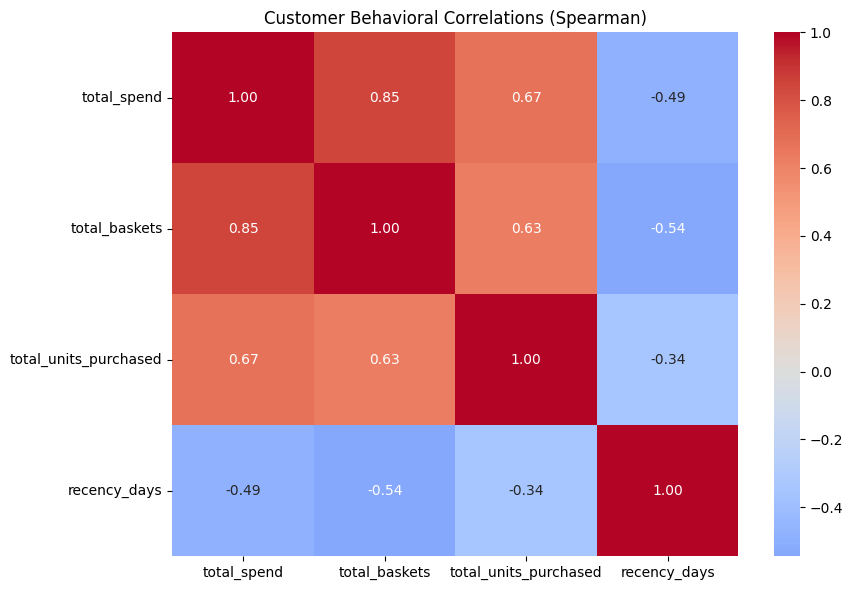

In [78]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    customer_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Customer Behavioral Correlations (Spearman)')
plt.tight_layout()
plt.show()

### Findings from the Spearman correlation
* **Total spend ↔ total baskets: 0.85**
    * Very strong positive relationship.
    * Customers who purchase more frequently tend to spend more overall.
* **Total spend ↔ total units purchased: 0.67**
    * Moderate-to-strong positive relationship.
    * Higher purchase volume is generally associated with higher spending.
* **Total baskets ↔ total units purchased: 0.63**
    * Moderate-to-strong positive relationship.
    * More frequent shoppers also tend to purchase more units.
* **Recency ↔ total baskets: -0.54**
    * Moderate negative relationship.
    * Customers with fewer days since their last purchase tend to have more baskets.
* **Recency ↔ total spend: -0.49**
    * Moderate negative relationship.
    * More recently active customers tend to have higher cumulative spending.
* **Recency ↔ total units purchased: -0.34**
    * Weaker negative relationship compared with the other behavioral measures.
    * Recency is related to purchase volume, but less strongly.

### 4.8.2. Product Performance Correlations

In [79]:
product_corr_cols = [
    'total_sales',
    'total_units_sold',
    'unique_households',
    'unique_baskets',
    'avg_unit_sales_value',
    'avg_retail_discount',
    'coupon_usage_rate'
]

product_corr = product_df[product_corr_cols].corr(method='spearman')

product_corr.round(2)

,total_sales,total_units_sold,unique_households,unique_baskets,avg_unit_sales_value,avg_retail_discount,coupon_usage_rate
total_sales,1.00,0.86,0.85,0.87,0.33,-0.25,0.35
total_units_sold,0.86,1.00,0.94,0.97,-0.15,-0.31,0.35
unique_households,0.85,0.94,1.00,0.97,-0.09,-0.29,0.36
unique_baskets,0.87,0.97,0.97,1.00,-0.10,-0.30,0.36
avg_unit_sales_value,0.33,-0.15,-0.09,-0.10,1.00,0.08,-0.01
avg_retail_discount,-0.25,-0.31,-0.29,-0.30,0.08,1.00,-0.23
coupon_usage_rate,0.35,0.35,0.36,0.36,-0.01,-0.23,1.00


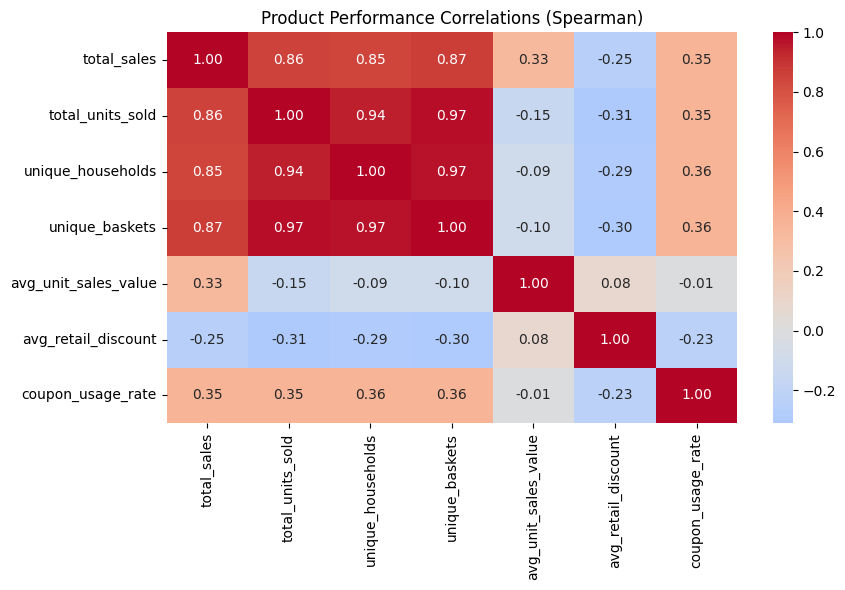

In [80]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    product_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Product Performance Correlations (Spearman)')
plt.tight_layout()
plt.show()

# 5. Feature Preparation / Engineering

## 5.1. Feature Preparation Overview

Feature preparation and engineering is the process of transforming the analytical datasets into structured, consistent, and model-ready features. The objective is to improve the representation of customer, product, and campaign behavior while preserving meaningful business information identified during EDA.

The feature engineering process builds upon the analytical tables created during the SQL stage and the patterns identified during exploratory data analysis. It includes feature selection, transformation, creation of derived variables, categorical encoding, and numerical feature preparation where required.

The resulting feature sets will serve as the foundation for subsequent analytical and modeling tasks.

In [81]:
# Inspecting the household_eda dataframe before feature engineering
print("Shape:", household_eda.shape)
print("\nColumn types:")
print(household_eda.dtypes)
print("\nMissing values:")
print(household_eda.isnull().sum())
print("\nBasic stats:")
household_eda.describe().T.round(2)

Shape: (2500, 21)

Column types:
household_key                 int64
total_baskets                 int64
active_days                   int64
unique_products               int64
total_units_purchased         int64
total_spend                 float64
avg_basket_value            float64
avg_retail_discount         float64
coupon_usage_rate           float64
recency_days                  int64
age_desc                     object
marital_status_code          object
income_desc                  object
homeowner_desc               object
hh_comp_desc                 object
household_size_desc          object
kid_category_desc            object
campaigns_assigned          float64
campaigns_redeemed          float64
coupons_redeemed            float64
campaign_redemption_rate    float64
dtype: object

Missing values:
household_key                  0
total_baskets                  0
active_days                    0
unique_products                0
total_units_purchased          0
total_spend    

,count,mean,std,min,25%,50%,75%,max
household_key,2500.0,1250.50,721.83,1.00,625.75,1250.50,1875.25,2500.00
total_baskets,2500.0,110.59,115.67,1.00,39.00,79.00,142.25,1300.00
active_days,2500.0,90.21,76.32,1.00,34.00,70.00,124.00,521.00
unique_products,2500.0,560.59,435.96,4.00,230.75,455.00,788.00,3159.00
total_units_purchased,2500.0,104274.25,244456.08,5.00,770.00,11084.50,87640.00,4479917.00
total_spend,2500.0,3222.99,3349.03,8.17,970.74,2157.75,4413.32,38319.79
avg_basket_value,2500.0,31.62,19.05,2.39,18.33,27.42,40.55,165.83
avg_retail_discount,2500.0,-0.56,0.28,-4.75,-0.64,-0.50,-0.41,-0.04
coupon_usage_rate,2500.0,0.01,0.02,0.00,0.00,0.00,0.01,0.26
recency_days,2500.0,25.57,62.79,0.00,1.00,6.00,20.00,657.00


## 5.2. Derived Feature Creation

Creating new business-meaningful features from existing columns to improve the representation of customer behavior.
-  Spending intensity: how much does the household spend per active shopping day?
-  Shopping frequency: how many baskets per active day?
-  Basket size: how many units per basket on average?
-  Product diversity: how many unique products relative to number of baskets?

In [82]:
features_df = household_eda.copy()

features_df['spend_per_active_day'] = (features_df['total_spend'] / features_df['active_days']).round(2)

features_df['baskets_per_active_day'] = (features_df['total_baskets'] / features_df['active_days']).round(4)

features_df['units_per_basket'] = (features_df['total_units_purchased'] / features_df['total_baskets']).round(2)

features_df['product_diversity_ratio'] = (features_df['unique_products'] / features_df['total_baskets']).round(4)

In [83]:
pd.set_option('display.width', 1000)
print("Derived features created:")
print(features_df[['spend_per_active_day', 'baskets_per_active_day', 
           'units_per_basket', 'product_diversity_ratio']].describe().T.round(2))

Derived features created:
                          count    mean      std   min    25%     50%     75%       max
spend_per_active_day     2500.0   36.12    21.09  2.39  21.30   31.51   46.10    187.31
baskets_per_active_day   2500.0    1.16     0.17  1.00   1.06    1.12    1.21      2.73
units_per_basket         2500.0  726.70  1239.62  1.59  13.51  137.47  965.78  16322.50
product_diversity_ratio  2500.0    6.52     3.98  0.23   3.88    5.64    8.20     51.20


## 5.3. Handling Missing Values

Two groups of missing data need to address:
1. **Campaign features** (916 households): These households were never assigned to any campaign.
2. **Demographic features** (1,699 households): No demographic information is available.

In [84]:
# Campaign features missing values

campaign_cols = ['campaigns_assigned', 'campaigns_redeemed', 
                 'coupons_redeemed', 'campaign_redemption_rate']

features_df[campaign_cols] = features_df[campaign_cols].fillna(0)

# Creating a binary flag: was this household ever targeted by a campaign?
features_df['was_campaign_targeted'] = (features_df['campaigns_assigned'] > 0).astype(int)

# Creating a binary flag: did this household ever redeem any campaign?
features_df['is_campaign_redeemer'] = (features_df['campaigns_redeemed'] > 0).astype(int)

print("Campaign missing values after fill:")
print(features_df[campaign_cols].isnull().sum())

print(f"\nHouseholds targeted by campaigns: {features_df['was_campaign_targeted'].sum()} / {len(features_df)}")
print(f"Households who redeemed: {features_df['is_campaign_redeemer'].sum()} / {len(features_df)}")
print(f"Redemption class balance: {features_df['is_campaign_redeemer'].value_counts(normalize=True).round(4).to_dict()}")

Campaign missing values after fill:
campaigns_assigned          0
campaigns_redeemed          0
coupons_redeemed            0
campaign_redemption_rate    0
dtype: int64

Households targeted by campaigns: 1584 / 2500
Households who redeemed: 434 / 2500
Redemption class balance: {0: 0.8264, 1: 0.1736}


In [85]:
# Demographic feature missing values

demo_cols = ['age_desc', 'marital_status_code', 'income_desc', 
             'homeowner_desc', 'hh_comp_desc', 'household_size_desc', 
             'kid_category_desc']

# Creating a flag indicating whether demographics are available
features_df['has_demographics'] = features_df['age_desc'].notna().astype(int)

# Filling the missing demographics with "Unknown"
features_df[demo_cols] = features_df[demo_cols].fillna('Unknown')

print("Demographic missing values after fill:")
print(features_df[demo_cols].isnull().sum())
print(f"\nHouseholds with demographics: {features_df['has_demographics'].sum()} / {len(features_df)}")

Demographic missing values after fill:
age_desc               0
marital_status_code    0
income_desc            0
homeowner_desc         0
hh_comp_desc           0
household_size_desc    0
kid_category_desc      0
dtype: int64

Households with demographics: 801 / 2500


## 5.4. Categorical Encoding

Encoding categorical demographic variables into numerical representations for modeling.

- **Ordinal encoding** for features with a natural order (age, income, household size)
- **Label encoding** for features without a natural order (marital status, homeowner, composition, kids)

In [86]:
# Ordinal encoding for ordered categories

# Age groups: natural order from youngest to oldest
age_order = {'19-24': 1, '25-34': 2, '35-44': 3, '45-54': 4, '55-64': 5, '65+': 6, 'Unknown': 0}
features_df['age_encoded'] = features_df['age_desc'].map(age_order)

# Income brackets: natural order from lowest to highest
income_order = {
    'Under 15K': 1, '15-24K': 2, '25-34K': 3, '35-49K': 4,
    '50-74K': 5, '75-99K': 6, '100-124K': 7, '125-149K': 8,
    '150-174K': 9, '175-199K': 10, '200-249K': 11, '250K+': 12,
    'Unknown': 0
}
features_df['income_encoded'] = features_df['income_desc'].map(income_order)

# Household size: natural order
size_order = {'1': 1, '2': 2, '3': 3, '4': 4, '5+': 5, 'Unknown': 0}
features_df['household_size_encoded'] = features_df['household_size_desc'].map(size_order)

print("Ordinal encoding applied:")
print(f"  age_encoded unique values: {sorted(features_df['age_encoded'].unique())}")
print(f"  income_encoded unique values: {sorted(features_df['income_encoded'].unique())}")
print(f"  household_size_encoded unique values: {sorted(features_df['household_size_encoded'].unique())}")

# Check for any unmapped values
for col in ['age_encoded', 'income_encoded', 'household_size_encoded']:
    unmapped = features_df[col].isnull().sum()
    if unmapped > 0:
        print(f"  WARNING: {col} has {unmapped} unmapped values!")

Ordinal encoding applied:
  age_encoded unique values: [0, 1, 2, 3, 4, 5, 6]
  income_encoded unique values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
  household_size_encoded unique values: [0, 1, 2, 3, 4, 5]


In [87]:
# Label encoding for unordered categories

# Marital status
marital_map = {'A': 1, 'B': 2, 'U': 0, 'Unknown': 0}
features_df['marital_encoded'] = features_df['marital_status_code'].map(marital_map)

# Homeowner status
homeowner_map = {
    'Homeowner': 1, 'Probable Owner': 2, 'Probable Homeowner': 2, 
    'Renter': 3, 'Probable Renter': 4, 
    'Unknown': 0
}
features_df['homeowner_encoded'] = features_df['homeowner_desc'].map(homeowner_map)

# Household composition
hh_comp_map = {
    '1 Adult Kids': 1, '2 Adults Kids': 2,
    '1 Adult No Kids': 3, '2 Adults No Kids': 4,
    'Single Male': 5, 'Single Female': 6,
    'Unknown': 0
}
features_df['hh_comp_encoded'] = features_df['hh_comp_desc'].map(hh_comp_map)

# Kid category
kid_map = {'None/Unknown': 1, '1': 2, '2': 3, '3+': 4, 'Unknown': 0}
features_df['kid_category_encoded'] = features_df['kid_category_desc'].map(kid_map)

print("Label encoding applied:")
for col in ['marital_encoded', 'homeowner_encoded', 'hh_comp_encoded', 'kid_category_encoded']:
    unmapped = features_df[col].isnull().sum()
    print(f"  {col}: {sorted(features_df[col].dropna().unique())} | unmapped: {unmapped}")

Label encoding applied:
  marital_encoded: [0, 1, 2] | unmapped: 0
  homeowner_encoded: [0, 1, 2, 3, 4] | unmapped: 0
  hh_comp_encoded: [0, 1, 2, 4, 5, 6] | unmapped: 0
  kid_category_encoded: [0, 1, 2, 3, 4] | unmapped: 0


## 5.5. Log Transformation of Skewed Features

Several behavioral features showed extreme right-skewness during EDA (Section 4.1–4.2). Log transformation reduces the influence of extreme outliers and makes distributions more suitable for our distance-based algorithms (K-Means) and linear models (Logistic Regression).

In [88]:
# Using log1p (log(1+x)) to handle zeros safely

skewed_cols = ['total_spend', 'total_baskets', 'total_units_purchased', 
               'active_days', 'unique_products']

for col in skewed_cols:
    features_df[f'{col}_log'] = np.log1p(features_df[col])

print("Log-transformed features created:")
print(features_df[[f'{col}_log' for col in skewed_cols]].describe().T.round(2))

Log-transformed features created:
                            count  mean   std   min   25%   50%    75%    max
total_spend_log            2500.0  7.55  1.14  2.22  6.88  7.68   8.39  10.55
total_baskets_log          2500.0  4.29  0.98  0.69  3.69  4.38   4.96   7.17
total_units_purchased_log  2500.0  9.05  2.74  1.79  6.65  9.31  11.38  15.32
active_days_log            2500.0  4.15  0.93  0.69  3.56  4.26   4.83   6.26
unique_products_log        2500.0  5.97  0.95  1.61  5.45  6.12   6.67   8.06


## 5.6. Feature Selection & Final Feature Matrix

Selecting the final set of features for modeling. The original string categorical columns are dropped in favor of their encoded versions. The household_key (ID column) is preserved as an index but excluded from the feature matrix.

In [89]:
# Final feature set

# Behavioral features (original scale)
behavioral_features = [
    'total_spend', 'total_baskets', 'active_days', 'unique_products',
    'total_units_purchased', 'avg_basket_value', 'avg_retail_discount',
    'coupon_usage_rate', 'recency_days'
]

# Derived features
derived_features = [
    'spend_per_active_day', 'baskets_per_active_day',
    'units_per_basket', 'product_diversity_ratio'
]

# Campaign features
campaign_features = [
    'campaigns_assigned', 'campaigns_redeemed', 'coupons_redeemed',
    'campaign_redemption_rate', 'was_campaign_targeted'
]

# Encoded demographic features
encoded_demo_features = [
    'age_encoded', 'income_encoded', 'household_size_encoded',
    'marital_encoded', 'homeowner_encoded', 'hh_comp_encoded',
    'kid_category_encoded', 'has_demographics'
]

# Log-transformed features
log_features = [f'{col}_log' for col in skewed_cols]

# Target variable
target = 'is_campaign_redeemer'

all_features = (behavioral_features + derived_features + 
                campaign_features + encoded_demo_features + log_features)

print(f"Total features selected: {len(all_features)}")
print(f"Target variable: {target}")
print(f"\nFeature groups:")
print(f"  Behavioral:  {len(behavioral_features)}")
print(f"  Derived:     {len(derived_features)}")
print(f"  Campaign:    {len(campaign_features)}")
print(f"  Demographic: {len(encoded_demo_features)}")
print(f"  Log-scaled:  {len(log_features)}")

Total features selected: 31
Target variable: is_campaign_redeemer

Feature groups:
  Behavioral:  9
  Derived:     4
  Campaign:    5
  Demographic: 8
  Log-scaled:  5


In [90]:
# The final modeling dataframe

# Keeping the household_key as index for traceability
df_model = features_df.set_index('household_key')[all_features + [target]].copy()

print("Final modeling dataset:")
print(f"  Shape: {df_model.shape}")
print(f"  Missing values: {df_model.isnull().sum().sum()}")
print(f"\nTarget distribution:")
print(df_model[target].value_counts())
print(f"\nFeature matrix preview:")
df_model.head()

Final modeling dataset:
  Shape: (2500, 32)
  Missing values: 0

Target distribution:
is_campaign_redeemer
0    2066
1     434
Name: count, dtype: int64

Feature matrix preview:


,total_spend,total_baskets,active_days,unique_products,total_units_purchased,avg_basket_value,avg_retail_discount,coupon_usage_rate,recency_days,spend_per_active_day,...,homeowner_encoded,hh_comp_encoded,kid_category_encoded,has_demographics,total_spend_log,total_baskets_log,total_units_purchased_log,active_days_log,unique_products_log,is_campaign_redeemer
household_key,,,,,,,,,,,,,,,,,,,,,
1,4330.16,86,79,677,1997,50.35,-0.4036,0.0614,5,54.81,...,1,4,1,1,8.373591,4.465908,7.599902,4.382027,6.519147,1
2,1954.34,45,45,546,834,43.43,-0.4692,0.0084,43,43.43,...,0,0,0,0,7.578319,3.828641,6.727432,3.828641,6.304449,0
3,2653.21,47,46,516,8540,56.45,-0.7323,0.0575,8,57.68,...,0,0,0,0,7.883902,3.871201,9.052633,3.850148,6.248043,0
4,1200.11,30,30,164,382,40.00,-0.3842,0.0033,84,40.00,...,0,0,0,0,7.091001,3.433987,5.948035,3.433987,5.105945,0
5,779.06,40,33,199,245,19.48,-0.5330,0.0000,8,23.61,...,0,0,0,0,6.659371,3.713572,5.505332,3.526361,5.298317,0


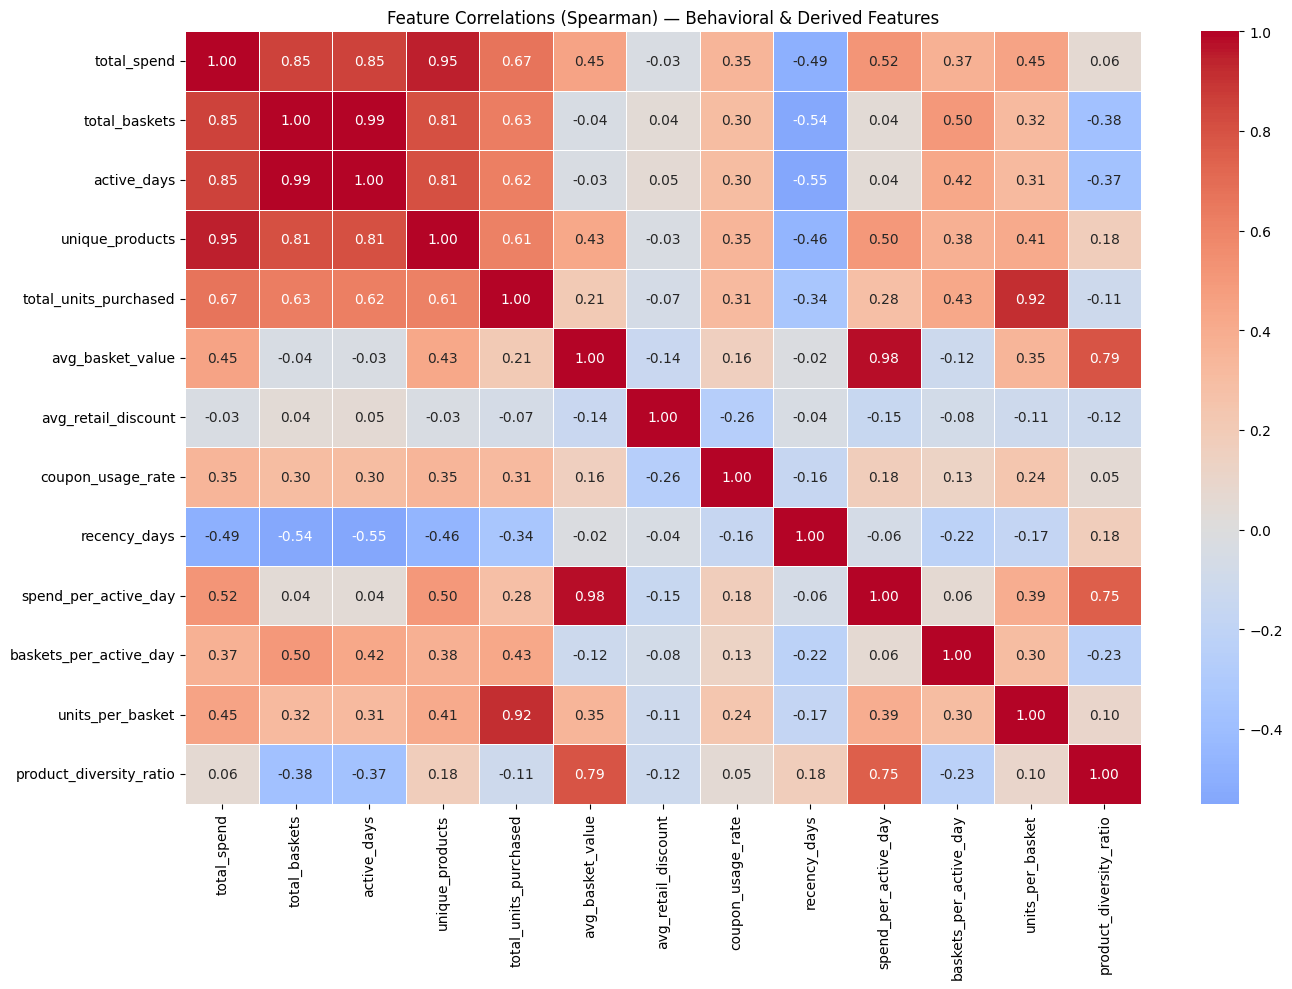

In [91]:
corr_cols = behavioral_features + derived_features
corr_matrix = df_model[corr_cols].corr(method='spearman').round(2)

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Feature Correlations (Spearman) — Behavioral & Derived Features')
plt.tight_layout()
plt.show()

In [92]:
# Saving the final engineered datasets

features_df.to_csv(r'D:\DataProject\Data\Processed\household_engineered.csv', index=False)

df_model.to_csv(r'D:\DataProject\Data\Processed\household_model_ready.csv')

print("Saved:")
print(f"  Full engineered dataset: D:\\DataProject\\Data\\Processed\\household_engineered.csv")
print(f"  Model-ready features:   D:\\DataProject\\Data\\Processed\\household_model_ready.csv")
print(f"\nfeatures_df shape: {features_df.shape}")
print(f"df_model shape: {df_model.shape}")

Saved:
  Full engineered dataset: D:\DataProject\Data\Processed\household_engineered.csv
  Model-ready features:   D:\DataProject\Data\Processed\household_model_ready.csv

features_df shape: (2500, 40)
df_model shape: (2500, 32)


## 5.7. Feature Engineering Summary

**Features created:**
- 4 derived behavioral features (spend intensity, shopping frequency, basket size, product diversity)
- 2 binary flags (campaign targeting, campaign redemption)
- 7 encoded demographic features + 1 demographics availability flag
- 5 log-transformed features for skewed distributions

**Missing data handled:**
- Campaign NaNs → filled with 0 (household was never targeted)
- Demographic NaNs → filled with "Unknown", encoded as 0

**Final modeling dataset:**
- 2,500 households
- 31 features + 1 target variable (`is_campaign_redeemer`)
- Zero missing values

The feature-engineered dataset is now ready for customer segmentation and machine learning.

# 6. Customer Segmentation

Customer segmentation groups households into meaningful business segments based on their purchasing behavior. This section uses two complementary approaches:

1. **RFM Scoring** — Extends the RFM quartile analysis from Section 4.4 by converting the exploratory quartiles into numerical scores and assigning business-meaningful segment labels.
2. **K-Means Clustering** — A data-driven approach using multiple behavioral features to discover natural customer groupings beyond RFM.

Both approaches will be compared to understand customer behavior from different perspectives.

## 6.1. RFM Scoring & Segment Assignment

In Section 4.4, RFM quartiles (Q1–Q4) were created and their behavioral patterns were examined through heatmaps and distribution plots. That analysis showed:

- High purchase frequency is strongly associated with high spending
- Recency provides additional separation within frequency/monetary groups
- The highest-value combination was Recency Q1 + Frequency Q4 (avg spend: 7,497)
- The lowest-value combination was Recency Q4 + Frequency Q1 (avg spend: 582)

This section converts those exploratory quartiles into numerical RFM scores (1–4) and assigns each household to a business-meaningful segment.

In [93]:
rfm_df = features_df[['household_key', 'recency_days', 'total_baskets', 'total_spend']].copy()

# Recency score: Q1 = lowest recency (most recent) = BEST = score 4
rfm_df['R_score'] = pd.qcut(
    rfm_df['recency_days'], q=4, labels=[4, 3, 2, 1]
).astype(int)

# Frequency score: Q4 = highest baskets = BEST = score 4
# Using rank(method='first') to handle duplicate bin edges
rfm_df['F_score'] = pd.qcut(
    rfm_df['total_baskets'].rank(method='first'), q=4, labels=[1, 2, 3, 4]
).astype(int)

# Monetary score: Q4 = highest spend = BEST = score 4
rfm_df['M_score'] = pd.qcut(
    rfm_df['total_spend'].rank(method='first'), q=4, labels=[1, 2, 3, 4]
).astype(int)

# Combined RFM average score
rfm_df['RFM_avg_score'] = ((rfm_df['R_score'] + rfm_df['F_score'] + rfm_df['M_score']) / 3).round(2)

# RFM string label for reference (e.g., "4-4-4")
rfm_df['RFM_label'] = (rfm_df['R_score'].astype(str) + '-' + 
                        rfm_df['F_score'].astype(str) + '-' + 
                        rfm_df['M_score'].astype(str))

print("RFM Score Distribution:")
print(rfm_df[['R_score', 'F_score', 'M_score', 'RFM_avg_score']].describe().T.round(2))
print(f"\nUnique RFM combinations: {rfm_df['RFM_label'].nunique()}")

RFM Score Distribution:
                count  mean   std  min   25%   50%   75%  max
R_score        2500.0  2.54  1.11  1.0  2.00  3.00  4.00  4.0
F_score        2500.0  2.50  1.12  1.0  1.75  2.50  3.25  4.0
M_score        2500.0  2.50  1.12  1.0  1.75  2.50  3.25  4.0
RFM_avg_score  2500.0  2.51  0.95  1.0  1.67  2.67  3.33  4.0

Unique RFM combinations: 57


In [94]:
# Assigning business-meaningful segment labels

def assign_rfm_segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    
    # Champions: Recent, frequent, high spenders
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    
    # Loyal Customers: Frequent buyers with good spending
    elif f >= 3 and m >= 3:
        return 'Loyal Customers'
    
    # Potential Loyalists: Recent customers with moderate frequency
    elif r >= 3 and f >= 2 and m >= 2:
        return 'Potential Loyalists'
    
    # At Risk: Were good customers but haven't purchased recently
    elif r <= 2 and f >= 3:
        return 'At Risk'
    
    # Needs Attention: Moderate across all dimensions
    elif r >= 2 and f >= 2:
        return 'Needs Attention'
    
    # Hibernating: Low recency, low frequency
    elif r <= 2 and f <= 2:
        return 'Hibernating'
    
    # Others
    else:
        return 'Others'

rfm_df['rfm_segment'] = rfm_df.apply(assign_rfm_segment, axis=1)

# Segment counts
segment_counts = rfm_df['rfm_segment'].value_counts()
print("RFM Segment Distribution:")
print(segment_counts)
print(f"\nTotal: {segment_counts.sum()}")

RFM Segment Distribution:
rfm_segment
Loyal Customers        821
Hibernating            637
Potential Loyalists    320
Needs Attention        288
Champions              226
Others                 131
At Risk                 77
Name: count, dtype: int64

Total: 2500


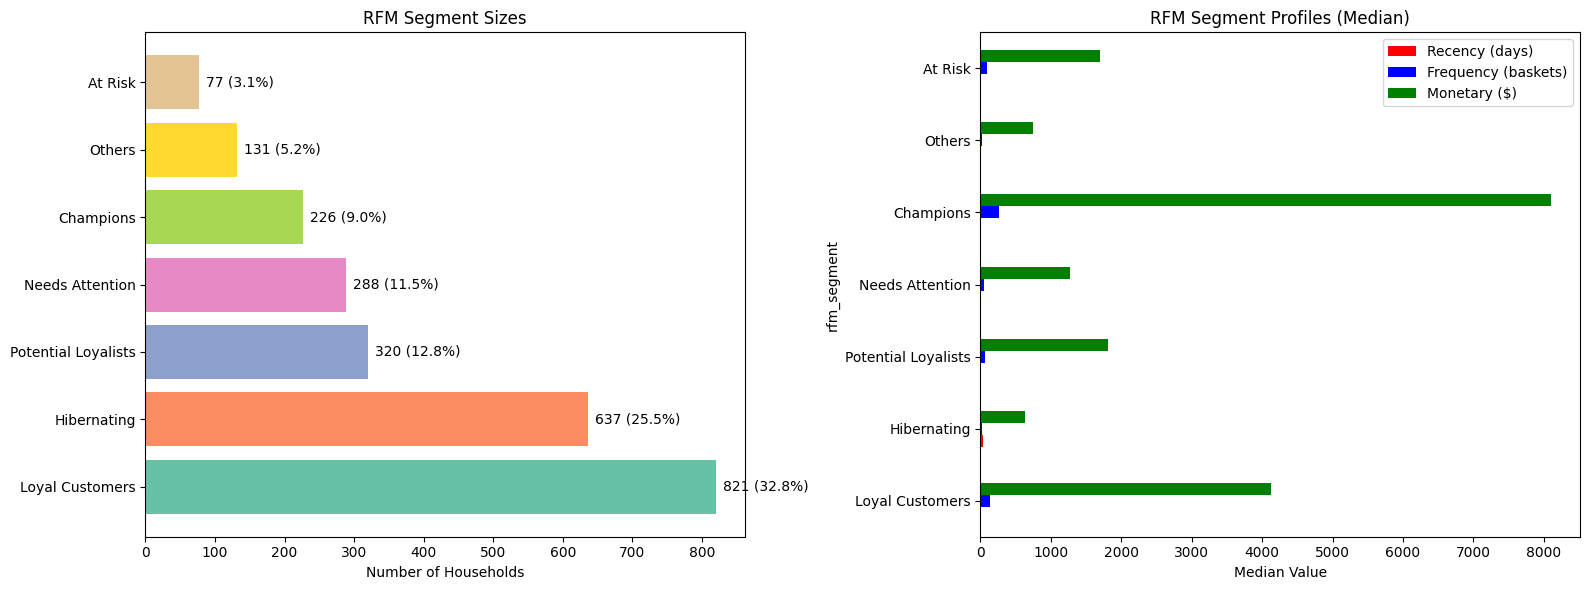

In [95]:
# RFM segments Visualization

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Segment count
segment_order = segment_counts.index.tolist()
colors = sns.color_palette('Set2', len(segment_order))

axes[0].barh(segment_order, segment_counts.values, color=colors)
axes[0].set_xlabel('Number of Households')
axes[0].set_title('RFM Segment Sizes')
for i, v in enumerate(segment_counts.values):
    axes[0].text(v + 10, i, f'{v} ({v/len(rfm_df)*100:.1f}%)', va='center')

# Segment median profiles
segment_stats = rfm_df.groupby('rfm_segment').agg(
    median_recency=('recency_days', 'median'),
    median_frequency=('total_baskets', 'median'),
    median_monetary=('total_spend', 'median')
).reindex(segment_order)

segment_stats.plot(kind='barh', ax=axes[1], color=['red', 'blue', 'green'])
axes[1].set_xlabel('Median Value')
axes[1].set_title('RFM Segment Profiles (Median)')
axes[1].legend(['Recency (days)', 'Frequency (baskets)', 'Monetary ($)'])

plt.tight_layout()
plt.show()

In [96]:
# Detailed segment profiles
segment_profile = rfm_df.groupby('rfm_segment').agg(
    count=('household_key', 'count'),
    median_recency=('recency_days', 'median'),
    median_frequency=('total_baskets', 'median'),
    median_monetary=('total_spend', 'median'),
    avg_rfm_score=('RFM_avg_score', 'mean')
).round(1)

segment_profile['pct_of_total'] = (segment_profile['count'] / segment_profile['count'].sum() * 100).round(1)
segment_profile = segment_profile.sort_values('avg_rfm_score', ascending=False)

print("RFM Segment Profiles:")
segment_profile.T

RFM Segment Profiles:


rfm_segment,Champions,Loyal Customers,Potential Loyalists,At Risk,Needs Attention,Others,Hibernating
count,226.0,821.0,320.0,77.0,288.0,131.0,637.0
median_recency,0.0,4.0,2.0,14.0,10.0,2.0,39.0
median_frequency,264.5,135.0,69.5,97.0,56.0,28.0,27.0
median_monetary,8109.2,4120.2,1811.6,1695.8,1274.0,739.7,633.9
avg_rfm_score,4.0,3.2,2.7,2.2,2.1,1.9,1.3
pct_of_total,9.0,32.8,12.8,3.1,11.5,5.2,25.5


## 6.2. K-Means Clustering

While RFM provides interpretable segments using three dimensions, K-Means clustering uses multiple behavioral features simultaneously to discover natural customer groupings. This captures more complex patterns that RFM alone may miss — including campaign behavior, coupon usage, product diversity, and shopping intensity.

**Features used for clustering:**
- Log-transformed behavioral: total_spend, total_baskets, active_days, unique_products
- Recency, average basket value, coupon usage rate
- Derived: spend_per_active_day, units_per_basket, product_diversity_ratio
- Campaign: campaign_redemption_rate, was_campaign_targeted

All features are standardized before clustering to ensure equal influence.

In [97]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [98]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --- Select clustering features ---
cluster_features = [
    'total_spend_log',
    'total_baskets_log', 
    'active_days_log',
    'unique_products_log',
    'recency_days',
    'spend_per_active_day',
    'units_per_basket',
    'product_diversity_ratio',
    'avg_basket_value',
    'coupon_usage_rate',
    'campaign_redemption_rate',
    'was_campaign_targeted'
]

# Extract clustering data
X_cluster = df_model[cluster_features].copy()

# Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print(f"Clustering data shape: {X_scaled.shape}")
print(f"Features used: {len(cluster_features)}")
print(f"\nScaled feature means (should be ~0):")
print(pd.DataFrame(X_scaled, columns=cluster_features).mean().round(4))

Clustering data shape: (2500, 12)
Features used: 12

Scaled feature means (should be ~0):
total_spend_log             0.0
total_baskets_log          -0.0
active_days_log             0.0
unique_products_log         0.0
recency_days               -0.0
spend_per_active_day        0.0
units_per_basket            0.0
product_diversity_ratio     0.0
avg_basket_value            0.0
coupon_usage_rate           0.0
campaign_redemption_rate   -0.0
was_campaign_targeted      -0.0
dtype: float64


K=2: Inertia=21590, Silhouette=0.3003
K=3: Inertia=18385, Silhouette=0.2702
K=4: Inertia=16115, Silhouette=0.2922
K=5: Inertia=14364, Silhouette=0.2956
K=6: Inertia=13181, Silhouette=0.2551
K=7: Inertia=12241, Silhouette=0.2246
K=8: Inertia=11482, Silhouette=0.2138
K=9: Inertia=10747, Silhouette=0.2176
K=10: Inertia=10081, Silhouette=0.2089


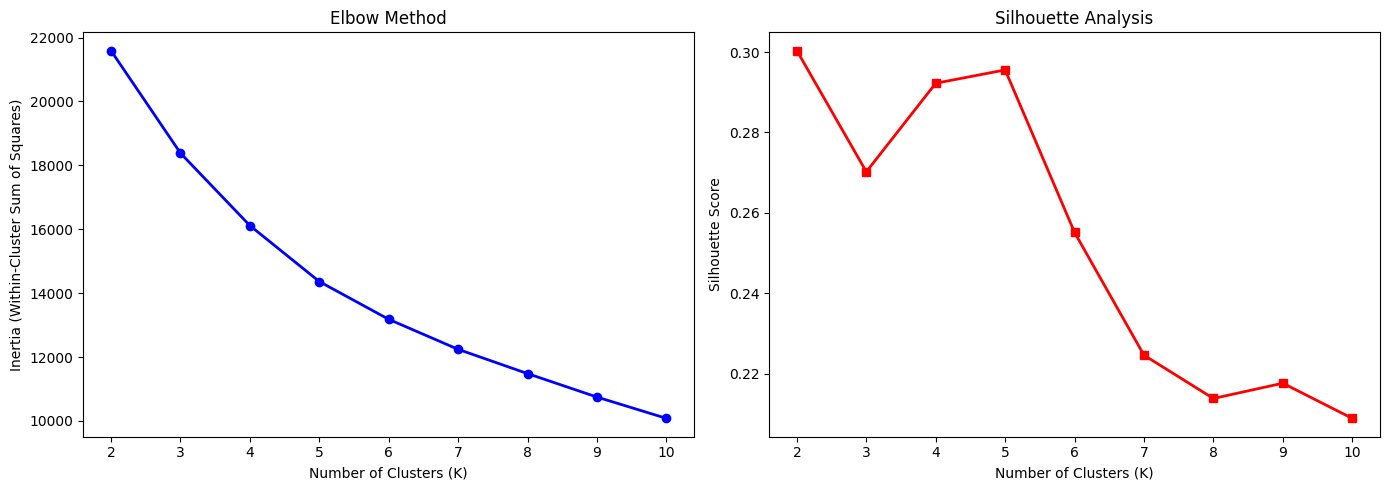


Best K by silhouette score: 2 (score: 0.3003)


In [99]:
# Find optimal number of clusters

K_range = range(2, 11)
inertia_values = []
silhouette_values = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(X_scaled)
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))
    print(f"K={k}: Inertia={kmeans.inertia_:.0f}, Silhouette={silhouette_score(X_scaled, labels):.4f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(K_range, inertia_values, 'bo-', linewidth=2)
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].set_title('Elbow Method')
axes[0].set_xticks(list(K_range))

# Silhouette plot
axes[1].plot(K_range, silhouette_values, 'rs-', linewidth=2)
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Analysis')
axes[1].set_xticks(list(K_range))

plt.tight_layout()
plt.show()

best_k = list(K_range)[silhouette_values.index(max(silhouette_values))]
print(f"\nBest K by silhouette score: {best_k} (score: {max(silhouette_values):.4f})")


 The highest silhouette score was at K=2 (coarsest split), but K=2 only separates "high spenders" from "low spenders" — too broad for actionable marketing decisions.

 Thus, selecting K=5 because:
 1. Its silhouette score (0.2956) is close to the maximum, indicating well-separated clusters.
 2. Five segments provide enough granularity for differentiating marketing strategies (e.g., targeting, retention, reactivation) without over-fragmenting a 2,500-household dataset.
 3. Business segmentation typically benefits from 4–6 segments to balance interpretability with actionable differentiation.


In [100]:
# Fit K-Means with K=5

optimal_k = 5
print(f"Using K = {optimal_k}")

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10, max_iter=300)
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to dataframes
features_df['cluster'] = cluster_labels
df_model['cluster'] = cluster_labels

print(f"\nCluster distribution:")
print(features_df['cluster'].value_counts().sort_index())
print(f"\nSilhouette score: {silhouette_score(X_scaled, cluster_labels):.4f}")

Using K = 5

Cluster distribution:
cluster
0     747
1    1111
2      62
3     250
4     330
Name: count, dtype: int64

Silhouette score: 0.2956


### 6.2.1. Cluster Profiling

Understanding what each cluster looks like by examining their behavioral characteristics.

In [101]:
# Profile each cluster

profile_cols = [
    'total_spend', 'total_baskets', 'active_days', 'unique_products',
    'recency_days', 'avg_basket_value', 'spend_per_active_day',
    'units_per_basket', 'product_diversity_ratio', 'coupon_usage_rate',
    'campaigns_assigned', 'campaigns_redeemed', 'campaign_redemption_rate',
    'was_campaign_targeted', 'is_campaign_redeemer'
]
# Median view for each cluster
cluster_medians = features_df.groupby('cluster')[profile_cols].median().round(2).T
print("Cluster Profiles (Median Values):")
cluster_medians

Cluster Profiles (Median Values):


cluster,0,1,2,3,4
total_spend,683.26,3082.47,164.03,5909.64,2561.23
total_baskets,34.00,128.00,7.00,158.00,46.00
active_days,31.00,111.00,6.00,135.00,43.00
unique_products,172.00,625.00,55.00,920.50,553.00
recency_days,15.00,3.00,293.50,2.00,9.00
avg_basket_value,20.76,25.26,24.40,40.64,58.26
spend_per_active_day,23.41,29.75,27.44,47.00,64.98
units_per_basket,15.27,190.56,13.57,1596.47,47.94
product_diversity_ratio,5.42,4.84,6.73,5.65,12.10
coupon_usage_rate,0.00,0.00,0.00,0.03,0.00


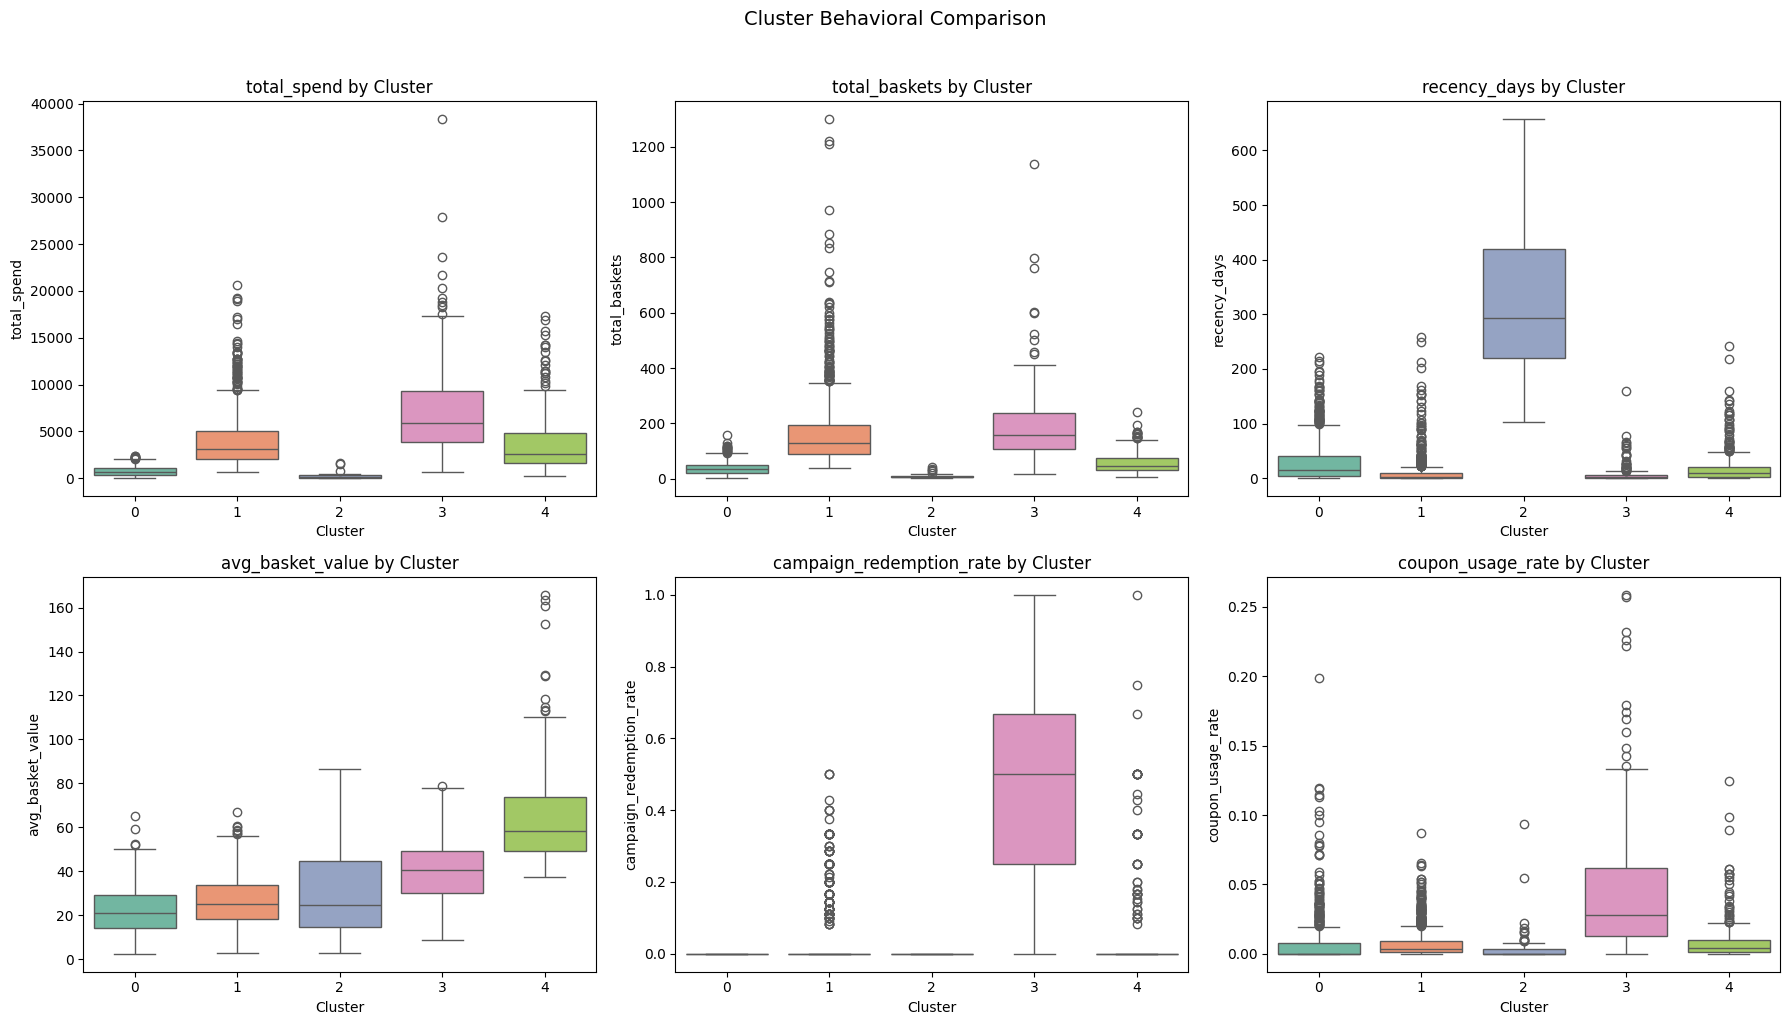

In [102]:
# Visualization of key metrics across clusters

compare_cols = ['total_spend', 'total_baskets', 'recency_days', 
                'avg_basket_value', 'campaign_redemption_rate', 'coupon_usage_rate']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(compare_cols):
    sns.boxplot(data=features_df, x='cluster', y=col, ax=axes[i], hue='cluster', palette='Set2', legend=False)
    axes[i].set_title(f'{col} by Cluster')
    axes[i].set_xlabel('Cluster')
plt.suptitle('Cluster Behavioral Comparison', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [103]:
# Cluster contribution analysis
cluster_summary = features_df.groupby('cluster').agg(
    n_households=('household_key', 'count'),
    total_revenue=('total_spend', 'sum'),
    avg_spend=('total_spend', 'mean'),
    avg_baskets=('total_baskets', 'mean'),
    avg_recency=('recency_days', 'mean'),
    pct_redeemers=('is_campaign_redeemer', 'mean')
).round(2)
cluster_summary['pct_households'] = (cluster_summary['n_households'] / cluster_summary['n_households'].sum() * 100).round(1)
cluster_summary['pct_revenue'] = (cluster_summary['total_revenue'] / cluster_summary['total_revenue'].sum() * 100).round(1)
cluster_summary['pct_redeemers'] = (cluster_summary['pct_redeemers'] * 100).round(1)
print("Cluster Summary:")
cluster_summary[['n_households', 'pct_households', 'pct_revenue', 'avg_spend', 
                  'avg_baskets', 'avg_recency', 'pct_redeemers']]

Cluster Summary:


,n_households,pct_households,pct_revenue,avg_spend,avg_baskets,avg_recency,pct_redeemers
cluster,,,,,,,
0,747,29.9,7.1,769.55,37.08,31.07,0.0
1,1111,44.4,54.9,3984.15,164.10,10.10,14.0
2,62,2.5,0.2,245.04,8.55,334.74,0.0
3,250,10.0,22.6,7271.18,190.12,7.01,93.0
4,330,13.2,15.2,3706.74,55.77,21.22,15.0


### 6.2.2. Cluster Visualization (PCA)

Since our clustering uses 12 features (dimensions), we reduce to 2 dimensions using PCA (Principal Component Analysis) for visualization while preserving as much of the variance as possible.

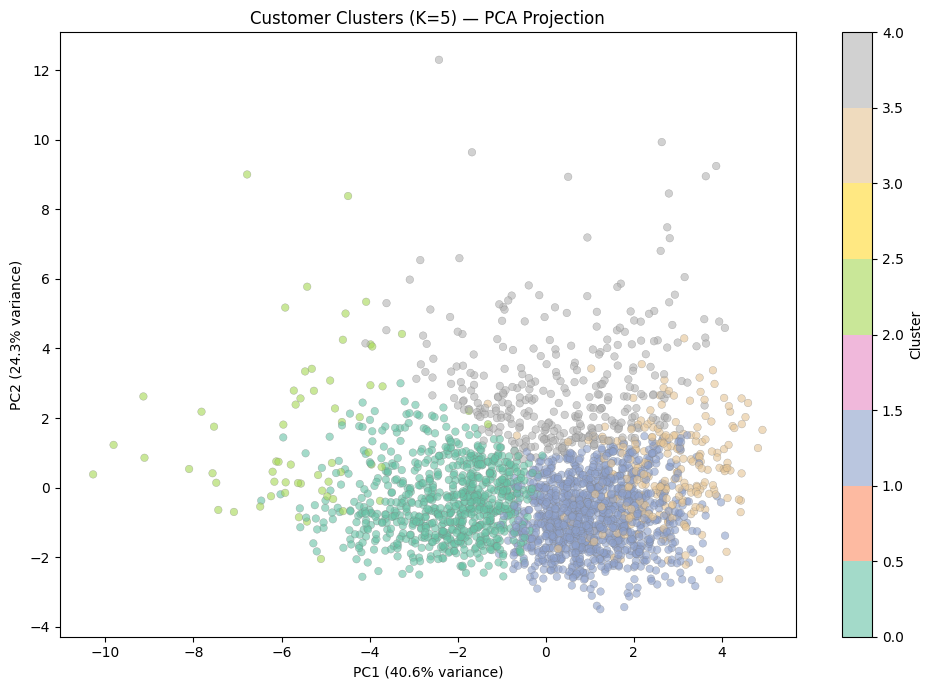

Total variance explained by 2 components: 64.8%


In [104]:
from sklearn.decomposition import PCA

# --- PCA 2D projection ---
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, 
                      cmap='Set2', alpha=0.6, s=30, edgecolors='grey', linewidth=0.3)
plt.colorbar(scatter, label='Cluster')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title(f'Customer Clusters (K={optimal_k}) — PCA Projection')
plt.tight_layout()
plt.show()

print(f"Total variance explained by 2 components: {pca.explained_variance_ratio_.sum()*100:.1f}%")

### 6.2.3. Cluster Naming

Assigning business-meaningful names to each cluster based on the cluster profiles above.

In [105]:
# Printing the medians to decide what name to give clusters
print("Cluster Medians for naming reference:")
print("=" * 80)
key_cols = ['total_spend', 'total_baskets', 'recency_days', 
            'avg_basket_value', 'campaign_redemption_rate']
naming_ref = features_df.groupby('cluster')[key_cols].median().round(1)
print(naming_ref)
print("=" * 80)
print("\nNaming guide:")
print("  - Highest spend + lowest recency → 'High-Value Champions'")
print("  - High frequency + moderate spend → 'Core Regulars'")
print("  - High recency + low frequency → 'Inactive / Lapsed'")
print("  - Low spend + low frequency + recent → 'New / Light Shoppers'")
print("  - Shop rarely but spend big per visit → 'Big-Basket Occasional'")

# Final cluster names
cluster_names = {
    0: 'Light Shoppers',
    1: 'Core Regulars',
    2: 'Lapsed',
    3: 'High-Value Champions',
    4: 'Big-Basket Occasional'
}

features_df['segment_name'] = features_df['cluster'].map(cluster_names)
df_model['segment_name'] = features_df['segment_name'].values
print(f"\nSegment distribution:")
print(features_df['segment_name'].value_counts())

Cluster Medians for naming reference:
         total_spend  total_baskets  recency_days  avg_basket_value  campaign_redemption_rate
cluster                                                                                      
0              683.3           34.0          15.0              20.8                       0.0
1             3082.5          128.0           3.0              25.3                       0.0
2              164.0            7.0         293.5              24.4                       0.0
3             5909.6          158.0           2.0              40.6                       0.5
4             2561.2           46.0           9.0              58.3                       0.0

Naming guide:
  - Highest spend + lowest recency → 'High-Value Champions'
  - High frequency + moderate spend → 'Core Regulars'
  - High recency + low frequency → 'Inactive / Lapsed'
  - Low spend + low frequency + recent → 'New / Light Shoppers'
  - Shop rarely but spend big per visit → 'Big-Basket Oc

## 6.3. RFM vs. Clustering Comparison

Comparing how the rule-based RFM segments (built on the Section 4.4 quartile analysis) align with the data-driven K-Means clusters.

In [106]:
features_df['rfm_segment'] = rfm_df['rfm_segment'].values

# Cross-tabulation
cross_tab = pd.crosstab(features_df['rfm_segment'], features_df['segment_name'], 
                         margins=True, margins_name='Total')

print("RFM Segments vs. K-Means Clusters:")
cross_tab

RFM Segments vs. K-Means Clusters:


segment_name,Big-Basket Occasional,Core Regulars,High-Value Champions,Lapsed,Light Shoppers,Total
rfm_segment,,,,,,
At Risk,0,59,6,0,12,77
Champions,7,147,72,0,0,226
Hibernating,119,36,8,62,412,637
Loyal Customers,70,610,139,0,2,821
Needs Attention,55,87,10,0,136,288
Others,32,0,0,0,99,131
Potential Loyalists,47,172,15,0,86,320
Total,330,1111,250,62,747,2500


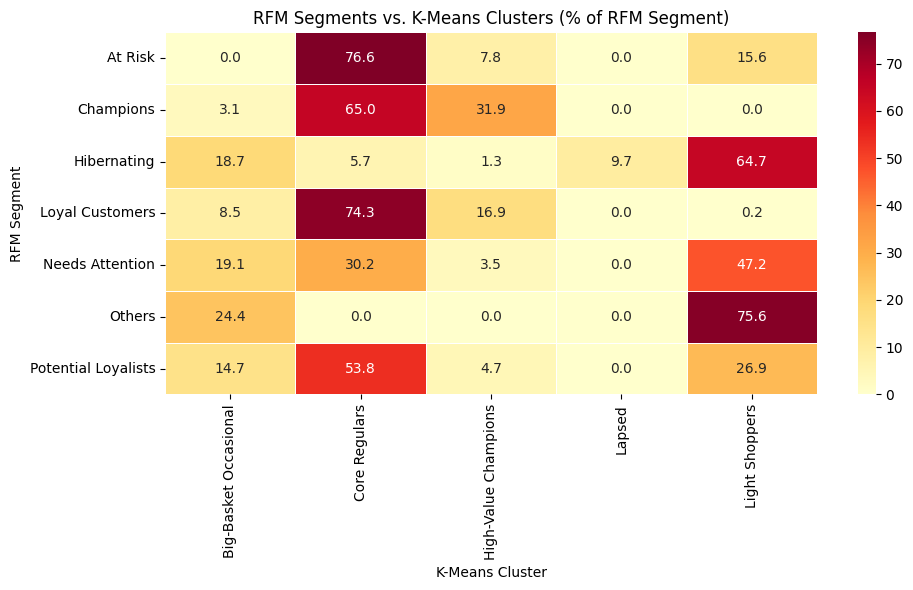

In [107]:
# Heatmap of overlap

cross_tab_pct = pd.crosstab(features_df['rfm_segment'], features_df['segment_name'], 
                              normalize='index').round(3) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(cross_tab_pct, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5)
plt.title('RFM Segments vs. K-Means Clusters (% of RFM Segment)')
plt.xlabel('K-Means Cluster')
plt.ylabel('RFM Segment')
plt.tight_layout()
plt.show()

In [108]:
# Saving the segmented dataset

features_df.to_csv(r'D:\DataProject\Data\Processed\household_segmented.csv', index=False)

print("Segmented dataset saved.")
print(f"Shape: {features_df.shape}")
print(f"\nColumns added during segmentation:")
print("  - cluster (K-Means cluster number)")
print("  - segment_name (business name for cluster)")
print("  - rfm_segment (RFM business segment)")

Segmented dataset saved.
Shape: (2500, 43)

Columns added during segmentation:
  - cluster (K-Means cluster number)
  - segment_name (business name for cluster)
  - rfm_segment (RFM business segment)


## 6.4. Segmentation Summary

**RFM Segmentation:**
- Extended the quartile analysis from Section 4.4 by converting Q1–Q4 labels into numerical scores (1–4)
- Assigned each household to a business-interpretable segment (Champions, Loyal, At Risk, Hibernating, etc.)
- Simple, transparent, and directly tied to the behavioral patterns observed in the EDA

**K-Means Clustering:**
- Data-driven segmentation using 12 behavioral and campaign features
- Discovers natural groupings without pre-defined rules
- Captures more complex multi-dimensional patterns beyond RFM (including campaign engagement, coupon behavior, product diversity)

**Key outputs for downstream analysis:**
- `rfm_segment` — RFM-based segment label
- `cluster` — K-Means cluster number
- `segment_name` — Business name for K-Means cluster

Both segmentation approaches will be used in the optimization stage to answer: *"Which customer segments should receive marketing attention?"* and *"Which customer groups offer the greatest potential value?"*